# 04-650 Mathematical Foundations of ML: project reference solution

**For the teaching team only. Do not distribute to students.**

This notebook works through the whole project specification (Parts A–F) from first principles.
Use it to check the numbers students report, and to see one sound way of setting up each
experiment. It is *a* solution, not *the* solution. Students may choose different splits,
seeds, learning rates, initialisations, K, λ or positive class, and every one of those
changes the numbers. Each part ends with a short **TA note** that says which results
should match closely whatever the student chose, and which depend on their choices.
The last cell collects the headline numbers in one **"reference values at a glance"** table.

| Convention | Value used here |
|---|---|
| Random seed | `SEED = 42` everywhere |
| Train/test split | 80/20; stratified for classification |
| Scaling | z-score with mean and population SD (`ddof=0`) from the **training rows only** |
| Positive class (breast cancer) | malignant = 1 (scikit-learn codes malignant as 0, so the label is flipped) |
| Library use | NumPy for every model; scikit-learn only to load data, split, compute metrics and give reference results |

## 0. Setup and shared building blocks

In [1]:
import copy
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris
from sklearn.metrics import (accuracy_score, adjusted_rand_score, confusion_matrix, f1_score,
                             log_loss, mean_absolute_error, precision_score, r2_score,
                             recall_score, roc_auc_score, silhouette_score)
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
np.set_printoptions(precision=4, suppress=True, linewidth=110)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Plot style: one validated categorical order, thin marks, recessive grid.
PAL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
       "magenta": "#e87ba4", "green": "#008300", "violet": "#6250d6", "red": "#e34948"}
SERIES = list(PAL.values())
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.prop_cycle": matplotlib.cycler(color=SERIES),
    "lines.linewidth": 1.6, "lines.markersize": 5, "legend.frameon": False,
    "figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
})

print(f"Python {platform.python_version()} | NumPy {np.__version__} | pandas {pd.__version__} | "
      f"Matplotlib {matplotlib.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.18 | NumPy 2.5.5 | pandas 3.1.1 | Matplotlib 3.11.2 | scikit-learn 1.9.1


In [2]:
def add_intercept(X):
    """Prepend a column of ones (the intercept) to a feature matrix."""
    return np.column_stack([np.ones(X.shape[0]), X])


def rmse(y, yhat):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(yhat)) ** 2)))


def cond2(A, rtol=None):
    """2-norm condition number from the singular values of A.

    Singular values at or below rtol * s_max count as zero (NumPy's matrix_rank default
    tolerance unless rtol is given). A rank-deficient matrix gets kappa = inf.
    Returns (kappa, singular_values, numerical_rank).
    """
    s = np.linalg.svd(A, compute_uv=False)
    if rtol is None:
        rtol = max(A.shape) * np.finfo(float).eps
    rank = int(np.sum(s > rtol * s[0]))
    kappa = np.inf if rank < min(A.shape) else s[0] / s[-1]
    return kappa, s, rank


class StandardScalerScratch:
    """z-score scaling with statistics learned in fit() and reused unchanged in transform()."""

    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)            # population SD (ddof=0), as in scikit-learn
        self.scale_[self.scale_ == 0] = 1.0    # leave constant columns unscaled
        return self

    def transform(self, X):
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

---
## Part A: Linear regression and matrix decompositions (`load_diabetes`)

### A1. Data preparation and formulation

In [3]:
diabetes = load_diabetes()
X_dia, y_dia = diabetes.data, diabetes.target
print("Feature matrix X:", X_dia.shape, "  target vector y:", y_dia.shape)
print("Features:", diabetes.feature_names)
print(f"Target: disease progression after one year, range [{y_dia.min():.0f}, {y_dia.max():.0f}], "
      f"mean {y_dia.mean():.1f}, SD {y_dia.std():.1f}")

XA_tr_raw, XA_te_raw, yA_tr, yA_te = train_test_split(X_dia, y_dia, test_size=0.2, random_state=SEED)
scaler_A = StandardScalerScratch().fit(XA_tr_raw)          # statistics from training rows only
XA_tr = add_intercept(scaler_A.transform(XA_tr_raw))       # design matrix [1 | standardised features]
XA_te = add_intercept(scaler_A.transform(XA_te_raw))
n_A, p_A = XA_tr.shape
kappa_A, sv_A, rank_A = cond2(XA_tr)

print(f"\nTraining design matrix: {XA_tr.shape}; numerical rank {rank_A} of {p_A} columns "
      f"(full column rank: {rank_A == p_A})")
print(f"Test design matrix:     {XA_te.shape}")
print("Test-set feature means after train-fitted scaling (close to, but not exactly, 0):",
      XA_te[:, 1:].mean(axis=0).round(2))

Feature matrix X: (442, 10)   target vector y: (442,)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target: disease progression after one year, range [25, 346], mean 152.1, SD 77.0

Training design matrix: (353, 11); numerical rank 11 of 11 columns (full column rank: True)
Test design matrix:     (89, 11)
Test-set feature means after train-fitted scaling (close to, but not exactly, 0): [-0.15 -0.02 -0.18 -0.12  0.06  0.08  0.1  -0.04 -0.13 -0.19]


* **Dimensions.** $X\in\mathbb{R}^{442\times 10}$ (age, sex, BMI, blood pressure, six serum
  measurements s1–s6), $\mathbf y\in\mathbb{R}^{442}$. The split gives 353 training rows
  and 89 test rows. The training design matrix with an intercept is $353\times 11$ and has
  full column rank 11.
* **Scaling.** `load_diabetes()` returns features that were already centred and scaled
  over all 442 rows. Re-standardising with training statistics undoes that, because
  z-scoring is invariant to any earlier affine rescaling of a column. The model therefore
  sees no test-set information.
* Test-set means are not exactly zero. That is expected: the test set is transformed with
  the training parameters, never re-fitted.

### A2. Least-squares derivation and implementation

**Gradient.** Expand the objective:
$$J(\boldsymbol\beta)=\frac{1}{2n}(X\boldsymbol\beta-\mathbf y)^\top(X\boldsymbol\beta-\mathbf y)
=\frac{1}{2n}\left(\boldsymbol\beta^\top X^\top X\boldsymbol\beta-2\boldsymbol\beta^\top X^\top\mathbf y+\mathbf y^\top\mathbf y\right).$$
Using $\nabla_{\boldsymbol\beta}(\boldsymbol\beta^\top A\boldsymbol\beta)=2A\boldsymbol\beta$ for symmetric $A$ and
$\nabla_{\boldsymbol\beta}(\boldsymbol\beta^\top\mathbf b)=\mathbf b$:
$$\nabla J(\boldsymbol\beta)=\frac1n\left(X^\top X\boldsymbol\beta-X^\top\mathbf y\right)=\frac1n X^\top(X\boldsymbol\beta-\mathbf y),
\qquad \nabla^2 J=\frac1n X^\top X\succeq 0 .$$
The Hessian is positive semidefinite, so $J$ is convex. Setting the gradient to zero gives the
**normal equations** $X^\top X\boldsymbol\beta=X^\top\mathbf y$, which have a unique solution exactly
when $X$ has full column rank (see A3).

**Normal equations.** Solve the $p\times p$ system with `np.linalg.solve` (LU factorisation).
Never form $(X^\top X)^{-1}$ explicitly: that costs more and is less accurate.

**Batch gradient descent.** $\boldsymbol\beta_{t+1}=\boldsymbol\beta_t-\eta\nabla J(\boldsymbol\beta_t)$. Write
$H=X^\top X/n$. The error $\mathbf e_t=\boldsymbol\beta_t-\hat{\boldsymbol\beta}$ obeys
$\mathbf e_{t+1}=(I-\eta H)\mathbf e_t$, so gradient descent converges from any start if and only if
$0<\eta<2/\lambda_{\max}(H)$. We use $\eta=1/\lambda_{\max}(H)=n/\sigma_{\max}(X)^2$. The slowest
error component then shrinks by a factor $1-1/\kappa_2(H)$ per step, which is why conditioning
sets the iteration count. Stopping rule: $\lVert\nabla J\rVert_2<10^{-8}$ or 100,000 iterations.

**QR.** With the reduced factorisation $X=QR$, $Q\in\mathbb R^{n\times p}$ has orthonormal
columns and $R\in\mathbb R^{p\times p}$ is upper triangular (non-singular when $X$ has full column rank):
$$\lVert X\boldsymbol\beta-\mathbf y\rVert_2^2=\lVert R\boldsymbol\beta-Q^\top\mathbf y\rVert_2^2+\lVert (I-QQ^\top)\mathbf y\rVert_2^2 .$$
The second term does not depend on $\boldsymbol\beta$. The first is zero when $R\boldsymbol\beta=\mathbf c$ with
$\mathbf c=Q^\top\mathbf y$. Because $R$ is upper triangular, solve it by **back substitution**, last row first:
$$\beta_p=\frac{c_p}{R_{pp}},\qquad \beta_i=\frac{1}{R_{ii}}\Big(c_i-\sum_{j>i}R_{ij}\beta_j\Big),\quad i=p-1,\dots,1 .$$
This costs $O(p^2)$ after the factorisation and never forms $X^\top X$, so its sensitivity is
governed by $\kappa(X)$ rather than $\kappa(X)^2$.

In [4]:
def back_substitution(R, c):
    """Solve R x = c for upper-triangular R with a non-zero diagonal, last row first."""
    p = R.shape[0]
    x = np.zeros(p)
    for i in range(p - 1, -1, -1):
        x[i] = (c[i] - R[i, i + 1:] @ x[i + 1:]) / R[i, i]
    return x


class LinearRegressionScratch:
    """Least squares J(b) = ||X b - y||^2 / (2n), solved by 'normal', 'qr' or 'gd'.

    With fit_intercept=True a column of ones is added; otherwise X is used as the design matrix.
    """

    def __init__(self, method="qr", fit_intercept=True, lr="auto", max_iter=100_000, tol=1e-8):
        self.method, self.fit_intercept = method, fit_intercept
        self.lr, self.max_iter, self.tol = lr, max_iter, tol

    def _design(self, X):
        return add_intercept(X) if self.fit_intercept else X

    @staticmethod
    def objective(beta, X1, y):
        r = X1 @ beta - y
        return 0.5 * float(np.mean(r ** 2))

    @staticmethod
    def gradient(beta, X1, y):
        return X1.T @ (X1 @ beta - y) / X1.shape[0]

    def fit(self, X, y):
        X1 = self._design(X)
        n, p = X1.shape
        if self.method == "normal":
            self.coef_ = np.linalg.solve(X1.T @ X1, X1.T @ y)
        elif self.method == "qr":
            Q, R = np.linalg.qr(X1, mode="reduced")
            self.coef_ = back_substitution(R, Q.T @ y)
        elif self.method == "gd":
            L = np.linalg.norm(X1, 2) ** 2 / n               # lambda_max(X^T X / n)
            self.lr_ = 1.0 / L if self.lr == "auto" else float(self.lr)
            beta = np.zeros(p)
            self.loss_history_ = [self.objective(beta, X1, y)]
            self.converged_ = False
            for it in range(1, self.max_iter + 1):
                g = self.gradient(beta, X1, y)
                if np.linalg.norm(g) < self.tol:
                    self.converged_ = True
                    break
                beta = beta - self.lr_ * g
                self.loss_history_.append(self.objective(beta, X1, y))
            self.n_iter_ = it
            self.coef_ = beta
        else:
            raise ValueError(f"unknown method {self.method!r}")
        return self

    def predict(self, X):
        return self._design(X) @ self.coef_


# XA_tr already contains the intercept column, so fit_intercept=False here.
lin_A = {m: LinearRegressionScratch(method=m, fit_intercept=False).fit(XA_tr, yA_tr)
         for m in ["normal", "qr", "gd"]}
gd_A = lin_A["gd"]
print(f"Gradient descent: eta = 1/L = {gd_A.lr_:.4f}, stopped after {gd_A.n_iter_} iterations "
      f"(converged: {gd_A.converged_})")

# Check the QR pieces and the hand-written back substitution.
Q_A, R_A = np.linalg.qr(XA_tr, mode="reduced")
print(f"||Q^T Q - I||_max = {np.abs(Q_A.T @ Q_A - np.eye(p_A)).max():.1e};  "
      f"max |below-diagonal of R| = {np.abs(np.tril(R_A, -1)).max():.1e};  "
      f"back substitution vs np.linalg.solve(R, Q^T y): "
      f"{np.abs(back_substitution(R_A, Q_A.T @ yA_tr) - np.linalg.solve(R_A, Q_A.T @ yA_tr)).max():.1e}")

Gradient descent: eta = 1/L = 0.2520, stopped after 7646 iterations (converged: True)
||Q^T Q - I||_max = 8.0e-15;  max |below-diagonal of R| = 0.0e+00;  back substitution vs np.linalg.solve(R, Q^T y): 3.6e-15


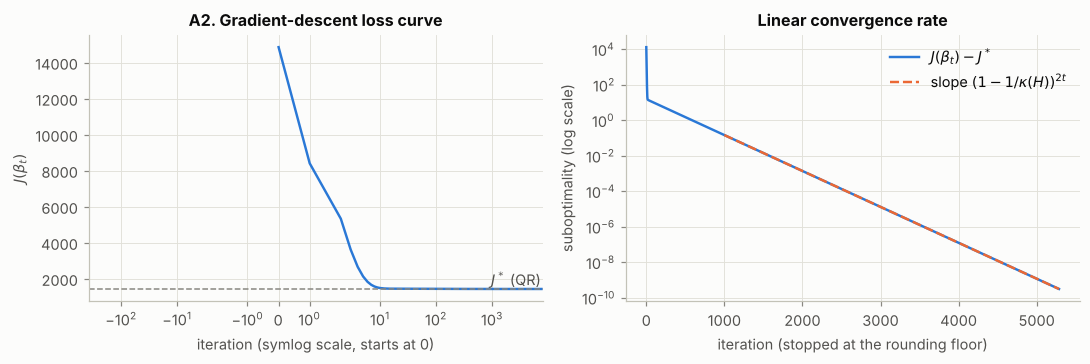

kappa(H) = 429.9: the slowest error component shrinks by 0.99767 per step.


In [5]:
J_star = LinearRegressionScratch.objective(lin_A["qr"].coef_, XA_tr, yA_tr)
hist = np.array(gd_A.loss_history_)
H_eig = np.linalg.eigvalsh(XA_tr.T @ XA_tr / n_A)
rate = 1 - H_eig[0] / H_eig[-1]                 # slowest contraction factor per step

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(np.arange(len(hist)), hist, color=PAL["blue"])
axes[0].axhline(J_star, color=MUTED, ls="--", lw=1)
axes[0].text(len(hist) * 0.98, J_star, " $J^*$ (QR)", color=INK2, va="bottom", ha="right")
axes[0].set(xscale="symlog", xlabel="iteration (symlog scale, starts at 0)", ylabel=r"$J(\beta_t)$",
            title="A2. Gradient-descent loss curve")
gap = hist - J_star
floor = 1e3 * np.finfo(float).eps * J_star          # below this, J differences are rounding noise
t_end = int(np.argmax(gap < floor)) if np.any(gap < floor) else len(gap)
t = np.arange(t_end)
axes[1].semilogy(t, gap[:t_end], color=PAL["blue"], label=r"$J(\beta_t)-J^*$")
t0 = 1000
axes[1].semilogy(t[t0:], gap[t0] * rate ** (2 * (t[t0:] - t0)), color=PAL["orange"], ls="--",
                 label=r"slope $(1-1/\kappa(H))^{2t}$")
axes[1].set(xlabel="iteration (stopped at the rounding floor)", ylabel="suboptimality (log scale)",
            title="Linear convergence rate")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"kappa(H) = {H_eig[-1] / H_eig[0]:.1f}: the slowest error component shrinks by {rate:.5f} per step.")

The loss falls fast in the first few iterations (the well-conditioned directions) and then
converges linearly. The slope on the log scale matches the theoretical
$(1-1/\kappa(H))^{2t}$ rate set by the smallest eigenvalue of $H$. That smallest eigenvalue
comes from the near-collinear serum measurements (A3).

### A3. SVD, rank and numerical stability

In [6]:
sv_table = pd.DataFrame({"sigma_i": sv_A, "sigma_i / sigma_1": sv_A / sv_A[0]},
                        index=[f"sigma_{i + 1}" for i in range(len(sv_A))])
display(sv_table.T)
XtX_A = XA_tr.T @ XA_tr
print(f"numerical rank (tol = max(n,p)*eps*sigma_1): {rank_A}")
print(f"kappa_2(X)        = sigma_1/sigma_p = {kappa_A:.2f}")
print(f"kappa_2(X)^2      = {kappa_A ** 2:.1f}")
print(f"kappa_2(X^T X)    = {np.linalg.cond(XtX_A):.1f}   (computed from the formed matrix)")
print(f"smallest eigenvalue of X^T X = {np.linalg.eigvalsh(XtX_A)[0]:.2f} > 0, so X^T X is positive definite")

# Which features make up the weakest direction?
_, _, Vt_A = np.linalg.svd(XA_tr, full_matrices=False)
v_min = pd.Series(Vt_A[-1], index=["intercept"] + diabetes.feature_names)
print("\nRight singular vector for sigma_min (largest loadings):")
print(v_min[v_min.abs().sort_values(ascending=False).index].head(5).round(3).to_string())

,sigma_1,sigma_2,sigma_3,sigma_4,sigma_5,sigma_6,sigma_7,sigma_8,sigma_9,sigma_10,sigma_11
sigma_i,37.4298,22.8413,21.0199,18.8901,18.7883,15.2439,14.4744,13.5532,12.3725,5.1671,1.8053
sigma_i / sigma_1,1.0000,0.6102,0.5616,0.5047,0.5020,0.4073,0.3867,0.3621,0.3306,0.1380,0.0482


numerical rank (tol = max(n,p)*eps*sigma_1): 11
kappa_2(X)        = sigma_1/sigma_p = 20.73
kappa_2(X)^2      = 429.9
kappa_2(X^T X)    = 429.9   (computed from the formed matrix)
smallest eigenvalue of X^T X = 3.26 > 0, so X^T X is positive definite

Right singular vector for sigma_min (largest loadings):
s1   -0.712
s2    0.557
s3    0.314
s5    0.273
s4    0.098


In [7]:
from sklearn.linear_model import LinearRegression  # reference implementation only

ref_A = LinearRegression().fit(XA_tr[:, 1:], yA_tr)
coef_table = pd.DataFrame({
    "normal eq.": lin_A["normal"].coef_,
    "QR": lin_A["qr"].coef_,
    "grad. descent": lin_A["gd"].coef_,
    "sklearn (reference)": np.r_[ref_A.intercept_, ref_A.coef_],
}, index=["intercept"] + diabetes.feature_names)
summary = pd.DataFrame({
    col: [np.abs(coef_table[col] - coef_table["QR"]).max(),
          rmse(yA_tr, XA_tr @ coef_table[col].to_numpy()),
          rmse(yA_te, XA_te @ coef_table[col].to_numpy())]
    for col in coef_table.columns
}, index=["max |coef - QR coef|", "train RMSE", "test RMSE"])
print("Coefficients (standardised features):")
display(coef_table)
display(summary)

Coefficients (standardised features):


,normal eq.,QR,grad. descent,sklearn (reference)
intercept,153.7365,153.7365,153.7365,153.7365
age,1.7538,1.7538,1.7538,1.7538
sex,-11.5118,-11.5118,-11.5118,-11.5118
bmi,25.6071,25.6071,25.6071,25.6071
bp,16.8289,16.8289,16.8289,16.8289
s1,-44.4489,-44.4489,-44.4489,-44.4489
s2,24.6410,24.6410,24.6410,24.6410
s3,7.6770,7.6770,7.6770,7.6770
s4,13.1388,13.1388,13.1388,13.1388
s5,35.1612,35.1612,35.1612,35.1612


,normal eq.,QR,grad. descent,sklearn (reference)
max |coef - QR coef|,1.6271e-12,0.0000,7.6945e-07,1.1369e-13
train RMSE,5.3559e+01,53.5588,5.3559e+01,5.3559e+01
test RMSE,5.3853e+01,53.8534,5.3853e+01,5.3853e+01


**Interpretation.**

* All 11 singular values are well above the rank tolerance, so $X$ has full column rank 11.
  The spread is moderate: $\sigma_1/\sigma_{11}\approx 20.7$, so $\kappa_2(X)\approx 20.7$ and
  $\kappa_2(X^\top X)\approx 430=\kappa_2(X)^2$. The weakest direction mixes s1 (total
  cholesterol), s2 (LDL), s3 (HDL) and s5: the serum measurements are nearly linearly dependent.
  Their individual coefficients (s1 ≈ −44, s2 ≈ +25) are therefore unstable and large with
  opposite signs, even though the predictions are stable.
* Normal equations, QR and the scikit-learn reference agree to $10^{-12}$ or better. Gradient
  descent agrees to about $10^{-6}$, the size the $10^{-8}$ gradient tolerance allows given
  $\lambda_{\min}(H)\approx 0.009$. All give the same test RMSE (≈ 53.85). At
  $\kappa\approx 20$ the choice of solver does not matter numerically; A4 shows when it does.

**Why forming $X^\top X$ can worsen conditioning.** Let $X=U\Sigma V^\top$ be the thin SVD with
$\sigma_1\ge\dots\ge\sigma_p>0$ (full column rank). Then
$$X^\top X=V\Sigma U^\top U\Sigma V^\top=V\Sigma^2V^\top .$$
This is an orthogonal diagonalisation, so the eigenvalues, and also the singular values, of the
symmetric PSD matrix $X^\top X$ are $\sigma_i^2$. Hence
$$\kappa_2(X^\top X)=\frac{\sigma_1^2}{\sigma_p^2}=\left(\frac{\sigma_1}{\sigma_p}\right)^2=\kappa_2(X)^2 .$$
A backward-stable solver loses roughly $\log_{10}\kappa$ significant digits. The normal
equations therefore lose about $2\log_{10}\kappa(X)$ digits, while QR (working on $X$ directly)
loses about $\log_{10}\kappa(X)$. Forming $X^\top X$ in floating point also rounds away any
direction with $\sigma_i/\sigma_1\lesssim\sqrt{u}\approx10^{-8}$: $\sigma_i^2$ falls below
$u\,\sigma_1^2$ and becomes indistinguishable from zero.

**When $X^\top X$ is positive definite.** For any $\mathbf v$,
$\mathbf v^\top X^\top X\mathbf v=\lVert X\mathbf v\rVert_2^2\ge 0$, so $X^\top X$ is always PSD. It is
zero exactly when $X\mathbf v=\mathbf 0$. So $X^\top X$ is **positive definite iff
$\operatorname{null}(X)=\{\mathbf 0\}$, i.e. $X$ has full column rank** (this needs $n\ge p$ and no
column that is an exact linear combination of the others). It is **only PSD** when
$\operatorname{rank}(X)<p$: for example when $p>n$, with duplicated or derived features, a
constant feature alongside the intercept, or one-hot dummies for every level plus an intercept.
Then the normal equations have infinitely many solutions; the SVD pseudo-inverse picks the
minimum-norm one.

### A4. Controlled conditioning experiment

**Design.** $n=200$, $x_1,x_3,z\sim\mathcal N(0,1)$ drawn once, and $x_2=x_1+\delta z$.
Shrinking $\delta$ is the only change between runs, so $\operatorname{corr}(x_1,x_2)\approx 1/\sqrt{1+\delta^2}\to 1$.
Design $X=[\mathbf 1, x_1, x_2, x_3]$ with true $\boldsymbol\beta^*=(1,2,3,-1)$.

1. **Numerical sensitivity (algorithm).** Use noise-free $\mathbf y=X\boldsymbol\beta^*$, so the exact
   least-squares solution is $\boldsymbol\beta^*$. Any error in the computed solution is then rounding error.
2. **Statistical sensitivity (problem).** Add noise $\varepsilon\sim\mathcal N(0,0.5^2)$, refit over
   300 noise draws and record the spread of $\hat\beta_1$. This spread is a property of the data,
   not of the solver: $\operatorname{Var}(\hat{\boldsymbol\beta})=\sigma^2(X^\top X)^{-1}$.

In [8]:
rng_A4 = np.random.default_rng(SEED)
n4 = 200
x1, x3, z4 = rng_A4.standard_normal((3, n4))
beta_true = np.array([1.0, 2.0, 3.0, -1.0])
deltas = 10.0 ** -np.arange(0, 9)                       # 1, 0.1, ..., 1e-8
noise = 0.5 * rng_A4.standard_normal((300, n4))         # same 300 noise vectors for every delta


def design_A4(delta):
    return np.column_stack([np.ones(n4), x1, x1 + delta * z4, x3])


def solve_normal(X, y):
    try:
        return np.linalg.solve(X.T @ X, X.T @ y)
    except np.linalg.LinAlgError:                       # X^T X singular to working precision
        return np.full(X.shape[1], np.nan)


def solve_qr(X, y):
    Q, R = np.linalg.qr(X, mode="reduced")
    return back_substitution(R, Q.T @ y)


rows = []
for d in deltas:
    X4 = design_A4(d)
    y_clean = X4 @ beta_true
    b_ne, b_qr = solve_normal(X4, y_clean), solve_qr(X4, y_clean)
    rel = lambda b: np.linalg.norm(b - beta_true) / np.linalg.norm(beta_true)
    Bqr = np.array([solve_qr(X4, y_clean + e) for e in noise])
    Bne = np.array([solve_normal(X4, y_clean + e) for e in noise])
    rows.append({
        "delta": d,
        "1 - corr(x1,x2)": 1 - np.corrcoef(x1, x1 + d * z4)[0, 1],
        "kappa(X)": cond2(X4, rtol=0)[0],
        "kappa(X)^2": cond2(X4, rtol=0)[0] ** 2,
        "kappa(X^T X) computed": np.linalg.cond(X4.T @ X4),
        "rel. error NE": rel(b_ne),
        "rel. error QR": rel(b_qr),
        "SD(b1) over noise": Bqr[:, 1].std(),
        "SD(b1+b2) over noise": (Bqr[:, 1] + Bqr[:, 2]).std(),
        "max |b_NE - b_QR| (noisy)": np.nanmax(np.abs(Bne - Bqr)) if np.isfinite(Bne).all() else np.nan,
    })
A4 = pd.DataFrame(rows).set_index("delta")
with pd.option_context("display.float_format", "{:.2e}".format):
    display(A4)

,"1 - corr(x1,x2)",kappa(X),kappa(X)^2,kappa(X^T X) computed,rel. error NE,rel. error QR,SD(b1) over noise,SD(b1+b2) over noise,max |b_NE - b_QR| (noisy)
delta,,,,,,,,,
1.00e+00,3.65e-01,2.40e+00,5.75e+00,5.75e+00,1.11e-15,3.64e-16,5.06e-02,3.84e-02,1.02e-14
1.00e-01,6.63e-03,1.75e+01,3.05e+02,3.05e+02,3.76e-14,3.45e-16,3.31e-01,3.84e-02,3.39e-13
1.00e-02,6.63e-05,1.75e+02,3.06e+04,3.06e+04,9.83e-12,1.03e-15,3.29e+00,3.84e-02,3.18e-11
1.00e-03,6.63e-07,1.75e+03,3.06e+06,3.06e+06,2.76e-10,2.76e-15,3.29e+01,3.84e-02,7.61e-09
1.00e-04,6.63e-09,1.75e+04,3.06e+08,3.06e+08,2.77e-09,4.01e-14,3.29e+02,3.84e-02,3.78e-05
1.00e-05,6.63e-11,1.75e+05,3.06e+10,3.06e+10,5.15e-06,5.13e-12,3.29e+03,3.84e-02,7.50e-03
1.00e-06,6.63e-13,1.75e+06,3.06e+12,3.06e+12,7.63e-04,1.71e-11,3.29e+04,3.84e-02,2.70e+01
1.00e-07,6.55e-15,1.75e+07,3.06e+14,2.91e+14,7.60e-02,5.78e-10,3.29e+05,3.84e-02,3.61e+04
1.00e-08,1.11e-15,1.75e+08,3.06e+16,1.38e+16,1.96e+00,1.72e-09,3.29e+06,3.84e-02,1.19e+07


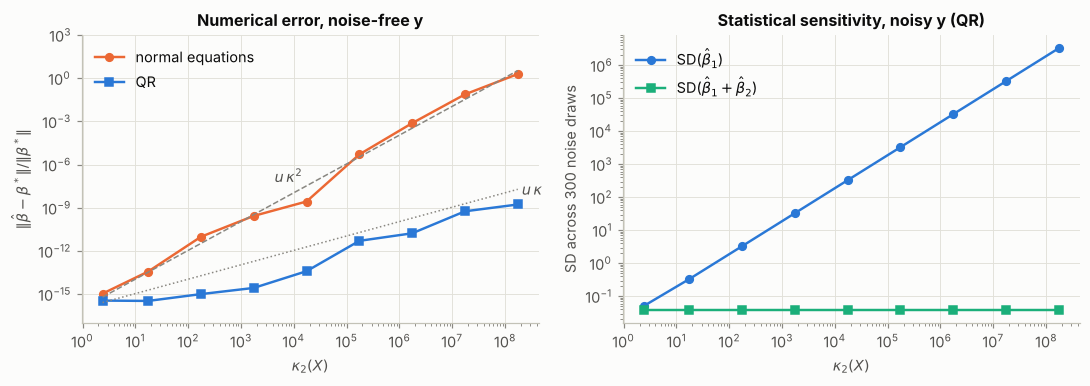

In [9]:
u = np.finfo(float).eps / 2
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
k = A4["kappa(X)"].to_numpy()
axes[0].loglog(k, A4["rel. error NE"], "o-", color=PAL["orange"], label="normal equations")
axes[0].loglog(k, A4["rel. error QR"], "s-", color=PAL["blue"], label="QR")
axes[0].loglog(k, u * k, color=MUTED, ls=":", lw=1)
axes[0].loglog(k, u * k ** 2, color=MUTED, ls="--", lw=1)
axes[0].text(k[-1], u * k[-1], r" $u\,\kappa$", color=INK2, va="center")
axes[0].text(k[4], u * k[4] ** 2, r"$u\,\kappa^2$ ", color=INK2, ha="right", va="bottom")
axes[0].set(xlabel=r"$\kappa_2(X)$", ylabel=r"$\|\hat\beta-\beta^*\|/\|\beta^*\|$",
            title="Numerical error, noise-free y", ylim=(1e-17, 1e3))
axes[0].legend(loc="upper left")
axes[1].loglog(k, A4["SD(b1) over noise"], "o-", color=PAL["blue"], label=r"SD($\hat\beta_1$)")
axes[1].loglog(k, A4["SD(b1+b2) over noise"], "s-", color=PAL["aqua"], label=r"SD($\hat\beta_1+\hat\beta_2$)")
axes[1].set(xlabel=r"$\kappa_2(X)$", ylabel="SD across 300 noise draws",
            title="Statistical sensitivity, noisy y (QR)")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**What the experiment shows.**

* $\kappa(X)$ grows like $1/\delta$, and $\kappa(X^\top X)$ tracks $\kappa(X)^2$ until it saturates
  near $1/u\approx10^{16}$. At that point the formed matrix is singular to working precision.
* **Normal equations versus QR.** With exact data, the QR error follows $u\,\kappa(X)$ and the
  normal-equation error follows $u\,\kappa(X)^2$. At $\kappa(X)\approx1.75\times10^5$ the normal
  equations keep only about 5 correct digits (relative error $5\times10^{-6}$, so about
  $2\log_{10}\kappa\approx10$ digits lost), while QR keeps about 11. At $\delta=10^{-8}$ the
  normal-equation solution is garbage (relative error ≈ 2), while QR is still accurate to about
  $2\times10^{-9}$. With noisy data the two solvers already disagree in the fifth significant figure
  at $\kappa(X)\approx10^4$, and by thousands at $\kappa(X)\ge10^6$.
* **The problem itself becomes sensitive too.** SD$(\hat\beta_1)$ grows like $1/\delta$ for *either*
  solver. The data cannot separate the effects of $x_1$ and $x_2$, but their sum
  $\hat\beta_1+\hat\beta_2$ stays well determined (SD ≈ 0.04 throughout). A better algorithm fixes
  the first problem, not the second.

**The role of the SVD.** Write
$\hat{\boldsymbol\beta}=\sum_i \frac{\mathbf u_i^\top\mathbf y}{\sigma_i}\mathbf v_i$. A tiny $\sigma_i$
divides whatever noise lies along $\mathbf u_i$ by a tiny number. The SVD (i) diagnoses the problem,
because the small $\sigma_i$ and their $\mathbf v_i$ say *which* combination of features is
unidentifiable (here $\mathbf v\propto(0,1,-1,0)$, "$x_1$ minus $x_2$"); and (ii) gives a remedy,
**truncated SVD**, which keeps only $\sigma_i>\tau\sigma_1$. That yields the minimum-norm solution in
the well-determined subspace. Ridge regression is the smooth version: it replaces $1/\sigma_i$ with
$\sigma_i/(\sigma_i^2+\lambda)$.

In [10]:
def solve_tsvd(X, y, rtol):
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    keep = s > rtol * s[0]
    return Vt[keep].T @ ((U[:, keep].T @ y) / s[keep]), int(keep.sum())


d_demo = 1e-6
X4 = design_A4(d_demo)
y4 = X4 @ beta_true + noise[0]
rng_new = np.random.default_rng(SEED + 1)               # fresh data from the same distribution
x1n, x3n, zn = rng_new.standard_normal((3, 1000))
X4_new = np.column_stack([np.ones(1000), x1n, x1n + d_demo * zn, x3n])
y4_new = X4_new @ beta_true + 0.5 * rng_new.standard_normal(1000)
b_tsvd, r_kept = solve_tsvd(X4, y4, rtol=1e-3)
demo = pd.DataFrame({
    "normal eq.": solve_normal(X4, y4),
    "QR": solve_qr(X4, y4),
    f"truncated SVD (rank {r_kept})": b_tsvd,
}, index=["b0 (intercept)", "b1 (x1)", "b2 (x2)", "b3 (x3)"]).T
demo["b1 + b2"] = demo["b1 (x1)"] + demo["b2 (x2)"]
demo["RMSE on fresh data"] = [rmse(y4_new, X4_new @ demo.iloc[i, :4].to_numpy()) for i in range(len(demo))]
print(f"delta = {d_demo:g}, kappa(X) = {cond2(X4, rtol=0)[0]:.2e}; true beta = {beta_true}")
display(demo)

delta = 1e-06, kappa(X) = 1.75e+06; true beta = [ 1.  2.  3. -1.]


,b0 (intercept),b1 (x1),b2 (x2),b3 (x3),b1 + b2,RMSE on fresh data
normal eq.,0.9848,-45173.4895,45178.4764,-1.0221,4.9869,0.4979
QR,0.9848,-45186.1681,45191.1550,-1.0221,4.9869,0.4979
truncated SVD (rank 3),0.9816,2.4923,2.4923,-1.0207,4.9846,0.4972


At $\delta=10^{-6}$, QR fits the noise along the unidentifiable direction and returns
$\hat\beta_1,\hat\beta_2$ in the thousands with opposite signs. Truncated SVD drops that one
direction and returns $\hat\beta_1\approx\hat\beta_2\approx2.5$, the minimum-norm split of the
identifiable sum $\beta_1+\beta_2=5$. On fresh data the prediction error is essentially unchanged:
the large coefficients are an artefact of the ill-posed direction, not real effects.

> **TA note (Part A).** For an 80/20 split with seed 42: test RMSE ≈ 53.85, κ(X) ≈ 20.7,
> κ(XᵀX) ≈ 430. Other splits give a test RMSE of roughly 50–58 and κ(X) of 19–23.
> **Whatever the split, all three methods must give the same test RMSE**, and that RMSE does not
> depend on whether the student standardised: with an intercept, a per-feature affine rescaling
> leaves the column space, and so the OLS predictions, unchanged. A visible gap between gradient
> descent and the others means it was stopped early. Things to check: `np.linalg.inv` used for the
> normal equations; QR solved with `inv(R)` and no explanation of back substitution; the proof of
> κ(XᵀX) = κ(X)² done only for square or symmetric X; an A4 experiment that reports only statistical
> variability and calls it numerical error.

---
## Part B: Probability, logistic regression and vector calculus (`load_breast_cancer`)

### B1. Probabilistic formulation

Let $Y\in\{0,1\}$ with **$Y=1$ meaning the tumour is malignant**, and let $\mathbf x\in\mathbb R^{30}$
be the standardised features. Write $\tilde{\mathbf x}=(1,\mathbf x)$, so $w_0$ is the intercept.
The model is
$$p(\mathbf x)=P(Y=1\mid\mathbf x;\mathbf w)=\sigma(\tilde{\mathbf x}^\top\mathbf w),\qquad
\sigma(z)=\frac{1}{1+e^{-z}} .$$

* $P(Y=1\mid\mathbf x)$ is a *number in (0, 1)* describing the conditional distribution of the
  outcome given the features. A **predicted label** $\hat y=\mathbb 1[p(\mathbf x)\ge\tau]$ is a
  *decision* derived from it. It depends on a threshold $\tau$ that encodes the costs of the two
  kinds of error. Two patients with $p=0.51$ and $p=0.99$ get the same label at $\tau=0.5$, but
  represent very different risks.
* **Numerical stability.** For $z\ll0$, $e^{-z}$ overflows, so compute
  $\sigma(z)=e^{z}/(1+e^{z})$ there. Never compute $\log\sigma(z)$ from $\sigma(z)$, because
  $\sigma$ rounds to 0 or 1 for $|z|\gtrsim 37$. Instead use the logit form of the loss,
  $-[y\log\sigma(z)+(1-y)\log(1-\sigma(z))]=\log(1+e^{z})-yz$, computed as
  `np.logaddexp(0, z) - y*z`.

In [11]:
bc = load_breast_cancer()
X_bc = bc.data
y_bc = (bc.target == 0).astype(int)                  # flip: malignant = 1
print("X:", X_bc.shape, "| malignant (y=1):", y_bc.sum(), "| benign (y=0):", (1 - y_bc).sum(),
      f"| prevalence {y_bc.mean():.3f}")

XB_tr_raw, XB_te_raw, yB_tr, yB_te = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=SEED, stratify=y_bc)
scaler_B = StandardScalerScratch().fit(XB_tr_raw)
XB_tr, XB_te = scaler_B.transform(XB_tr_raw), scaler_B.transform(XB_te_raw)
print("train:", XB_tr.shape, "test:", XB_te.shape)

X: (569, 30) | malignant (y=1): 212 | benign (y=0): 357 | prevalence 0.373
train: (455, 30) test: (114, 30)


### B2. Likelihood and loss derivation

**1. Log-likelihood.** With $p_i=\sigma(\tilde{\mathbf x}_i^\top\mathbf w)$ and conditionally independent observations,
$$\ell(\mathbf w)=\log L(\mathbf w)=\sum_{i=1}^n\Big[y_i\log p_i+(1-y_i)\log(1-p_i)\Big].$$

**2. NLL = binary cross-entropy.** $-\ell(\mathbf w)=\sum_i \mathrm{BCE}(y_i,p_i)$ with
$\mathrm{BCE}(y,p)=-[y\log p+(1-y)\log(1-p)]$. Since $\log$ is strictly increasing,
$\arg\max L=\arg\max\ell=\arg\min(-\ell)$. Dividing by $n>0$ does not move the minimiser, so
maximum likelihood is the same as minimising the average BCE,
$J(\mathbf w)=\frac1n\sum_i\mathrm{BCE}(y_i,p_i)$.

**3. Gradient.** $\sigma'(z)=\sigma(z)(1-\sigma(z))$, so $\nabla_{\mathbf w}p_i=p_i(1-p_i)\tilde{\mathbf x}_i$, and
$$\nabla_{\mathbf w}\big[y_i\log p_i+(1-y_i)\log(1-p_i)\big]
=\Big(\frac{y_i}{p_i}-\frac{1-y_i}{1-p_i}\Big)p_i(1-p_i)\tilde{\mathbf x}_i=(y_i-p_i)\tilde{\mathbf x}_i .$$
Therefore
$$\nabla J(\mathbf w)=\frac1n\sum_i(p_i-y_i)\tilde{\mathbf x}_i=\frac1n\tilde X^\top(\mathbf p-\mathbf y),\qquad
\nabla^2J=\frac1n\tilde X^\top\operatorname{diag}\big(p_i(1-p_i)\big)\tilde X\succeq0 .$$
$J$ is convex. Because $p(1-p)\le\frac14$, the gradient is $L$-Lipschitz with
$L=\sigma_{\max}(\tilde X)^2/(4n)$, and $\eta=1/L$ guarantees the loss never increases. The code
below uses this as its `lr="auto"` step size.

**4. Meaning of the output.** $p(\mathbf x)$ estimates the long-run fraction of malignant cases
among patients who share feature vector $\mathbf x$, *if* the model is correctly specified and
calibrated. Any single patient's outcome is one Bernoulli draw: $p=0.9$ still leaves a 10 % chance
that the tumour is benign. One "surprising" outcome does not falsify the model, and calibration can
only be judged over groups of predictions. The probability is also conditional on the modelling
assumptions: log-odds linear in $\mathbf x$, a population like the training data, and independent cases.

### B3. From-scratch implementation

In [12]:
def sigmoid(z):
    """Numerically stable logistic function (no overflow for large |z|)."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def bce_from_logits(z, y):
    """Mean binary cross-entropy, computed from logits z = X w: mean(log(1 + e^z) - y z)."""
    return float(np.mean(np.logaddexp(0.0, z) - y * z))


class LogisticRegressionScratch:
    """Binary logistic regression trained by batch gradient descent.

    Objective: mean BCE + (l2 / 2) * ||w without intercept||^2.
    lr="auto" uses 1/L with L = sigma_max(X1)^2 / (4n) + l2 (Lipschitz constant of the gradient).
    Stops when ||grad||_2 < tol or after max_iter iterations.
    """

    def __init__(self, lr="auto", max_iter=10_000, tol=1e-6, l2=0.0, fit_intercept=True):
        self.lr, self.max_iter, self.tol = lr, max_iter, tol
        self.l2, self.fit_intercept = l2, fit_intercept

    def _design(self, X):
        return add_intercept(X) if self.fit_intercept else X

    def _mask(self, p):
        m = np.ones(p)
        if self.fit_intercept:
            m[0] = 0.0                      # the intercept is not penalised
        return m

    def objective(self, w, X1, y):
        return bce_from_logits(X1 @ w, y) + 0.5 * self.l2 * float(np.sum((self._mask(len(w)) * w) ** 2))

    def gradient(self, w, X1, y):
        return X1.T @ (sigmoid(X1 @ w) - y) / X1.shape[0] + self.l2 * self._mask(len(w)) * w

    def fit(self, X, y):
        X1 = self._design(X)
        n, p = X1.shape
        mask = self._mask(p)
        L = np.linalg.norm(X1, 2) ** 2 / (4 * n) + self.l2
        self.lr_ = 1.0 / L if self.lr == "auto" else float(self.lr)
        w = np.zeros(p)
        self.loss_history_, self.grad_norm_history_, self.weight_norm_history_ = [], [], []
        self.converged_ = False
        for it in range(1, self.max_iter + 1):
            z = X1 @ w
            g = X1.T @ (sigmoid(z) - y) / n + self.l2 * mask * w
            self.loss_history_.append(bce_from_logits(z, y) + 0.5 * self.l2 * float(np.sum((mask * w) ** 2)))
            gn = float(np.linalg.norm(g))
            self.grad_norm_history_.append(gn)
            self.weight_norm_history_.append(float(np.linalg.norm(mask * w)))
            if gn < self.tol:
                self.converged_ = True
                break
            w = w - self.lr_ * g
        self.n_iter_ = it
        self.coef_ = w
        return self

    def decision_function(self, X):
        return self._design(X) @ self.coef_

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


print("sigmoid at extremes:", sigmoid(np.array([-1000.0, -40.0, 0.0, 40.0, 1000.0])))
print("BCE at extreme logits (finite, no warnings):", bce_from_logits(np.array([-1000.0, 1000.0]), np.array([1, 0])))

sigmoid at extremes: [0.  0.  0.5 1.  1. ]
BCE at extreme logits (finite, no warnings): 1000.0


### B4. Gradient verification and optimisation experiments

**1. Finite-difference check.** Central differences,
$\partial J/\partial w_j\approx[J(\mathbf w+h\mathbf e_j)-J(\mathbf w-h\mathbf e_j)]/(2h)$ with
$h=10^{-6}$, on a random problem with 8 samples and 4 features, with and without the L2 term.

In [13]:
rng_fd = np.random.default_rng(SEED)
X_fd = add_intercept(rng_fd.standard_normal((8, 4)))
y_fd = rng_fd.integers(0, 2, size=8)
w_fd = rng_fd.standard_normal(5)
h = 1e-6
for l2 in [0.0, 0.3]:
    m = LogisticRegressionScratch(l2=l2)
    g_an = m.gradient(w_fd, X_fd, y_fd)
    g_num = np.array([(m.objective(w_fd + h * e, X_fd, y_fd) - m.objective(w_fd - h * e, X_fd, y_fd)) / (2 * h)
                      for e in np.eye(5)])
    print(f"l2 = {l2}: analytical {g_an.round(6)}\n          numerical  {g_num.round(6)}\n"
          f"          max |difference| = {np.abs(g_an - g_num).max():.2e}")

l2 = 0.0: analytical [ 0.4538 -0.1336 -0.3271  0.4227 -0.0318]
          numerical  [ 0.4538 -0.1336 -0.3271  0.4227 -0.0318]
          max |difference| = 8.37e-11
l2 = 0.3: analytical [ 0.4538 -0.3857 -0.5745  0.6179  0.1912]
          numerical  [ 0.4538 -0.3857 -0.5745  0.6179  0.1912]
          max |difference| = 7.80e-11


The maximum absolute difference is about $10^{-10}$. That is the size expected from central
differences (truncation error $O(h^2)\approx10^{-12}$ plus rounding $O(u/h)\approx10^{-10}$), so the
analytical gradient is correct. A bug, such as a missing $1/n$, a sign error or penalising the
intercept, would give differences of order $10^{-2}$ to $10^{0}$.

**2. Learning rates.** The data are standardised and $L=\sigma_{\max}(\tilde X)^2/(4n)$, so
$\eta\le 1/L$ is guaranteed to decrease the loss.

L = sigma_max^2/(4n) = 3.345  ->  safe step 1/L = 0.299, 2/L = 0.598


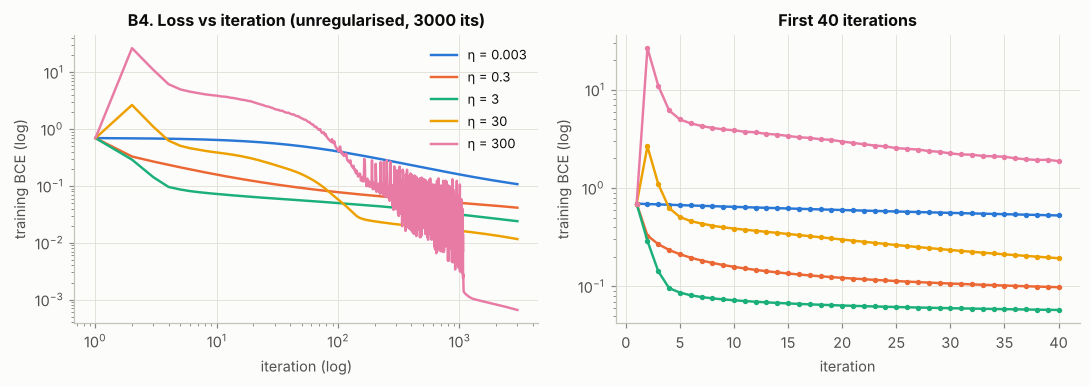

,η / (1/L),loss increases,max BCE seen,final train BCE,||w|| at end,train accuracy,test accuracy,test log-loss
η = 0.003,0.0100,0,0.6931,0.1073,1.5000,0.9780,0.9737,0.1065
η = 0.3,1.0034,0,0.6931,0.0414,6.1652,0.9912,0.9737,0.1131
η = 3,10.0335,0,0.6931,0.0240,16.2194,0.9890,0.9737,0.2532
η = 30,100.3354,1,2.6485,0.0116,46.6827,0.9978,0.9386,0.6903
η = 300,1003.3542,553,26.4553,0.0007,268.2007,1.0000,0.9474,1.6853


In [14]:
X1_B = add_intercept(XB_tr)
L_B = np.linalg.norm(X1_B, 2) ** 2 / (4 * len(X1_B))
print(f"L = sigma_max^2/(4n) = {L_B:.3f}  ->  safe step 1/L = {1 / L_B:.3f}, 2/L = {2 / L_B:.3f}")

lrs = [0.003, 0.3, 3.0, 30.0, 300.0]
runs_lr = {lr: LogisticRegressionScratch(lr=lr, max_iter=3000, tol=1e-10).fit(XB_tr, yB_tr) for lr in lrs}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for i, lr in enumerate(lrs):
    hst = runs_lr[lr].loss_history_
    axes[0].plot(np.arange(1, len(hst) + 1), hst, color=SERIES[i], label=f"η = {lr:g}")
    axes[1].plot(np.arange(1, 41), hst[:40], "o-", ms=2.5, color=SERIES[i], label=f"η = {lr:g}")
axes[0].set(xscale="log", yscale="log", xlabel="iteration (log)", ylabel="training BCE (log)",
            title="B4. Loss vs iteration (unregularised, 3000 its)")
axes[1].set(yscale="log", xlabel="iteration", ylabel="training BCE (log)", title="First 40 iterations")
axes[0].legend(ncol=1, fontsize=8.5)
plt.tight_layout()
plt.show()

lr_tab = pd.DataFrame({
    "η / (1/L)": [lr * L_B for lr in lrs],
    "loss increases": [int(np.sum(np.diff(runs_lr[lr].loss_history_) > 1e-12)) for lr in lrs],
    "max BCE seen": [max(runs_lr[lr].loss_history_) for lr in lrs],
    "final train BCE": [runs_lr[lr].loss_history_[-1] for lr in lrs],
    "||w|| at end": [np.linalg.norm(runs_lr[lr].coef_[1:]) for lr in lrs],
    "train accuracy": [accuracy_score(yB_tr, runs_lr[lr].predict(XB_tr)) for lr in lrs],
    "test accuracy": [accuracy_score(yB_te, runs_lr[lr].predict(XB_te)) for lr in lrs],
    "test log-loss": [log_loss(yB_te, runs_lr[lr].predict_proba(XB_te)) for lr in lrs],
}, index=[f"η = {lr:g}" for lr in lrs])
display(lr_tab)

**Interpretation.** (Unregularised model, 3000 iterations each.)

* **η = 0.003 (slow progress).** The loss decreases monotonically but is still far above the others
  after 3000 iterations: each step is 100× smaller than the safe $1/L$.
* **η = 0.3 ≈ 1/L (guaranteed monotone).** Smooth, monotone decrease, as the theory promises.
* **η = 3 (≈ 10/L, still monotone).** $L$ is a *worst-case* bound that uses $p(1-p)\le\tfrac14$. Once
  predictions move away from 0.5 the real curvature is much smaller, so a step above $2/L$ can still
  decrease the loss every time.
* **η = 30 and 300 (overshoot and oscillation).** The very first step from $\mathbf w=\mathbf 0$, where
  the curvature really is $L$, overshoots: the loss jumps from 0.69 to about 2.6 (η = 30) or about 26
  (η = 300). After that it falls, but non-monotonically: η = 300 increases the loss on hundreds of the
  3000 steps. With a naive `np.log(sigmoid(z))` instead of the logit form, these are the runs that
  produce `inf`/`nan`.
* **The surprise: the largest steps reach the *lowest* training loss.** This is not a contradiction.
  The training set is linearly separable (certified below), so the unregularised loss has **no
  minimiser**: it tends to 0 only as $\lVert\mathbf w\rVert\to\infty$. A big step just travels faster
  towards infinity. ‖w‖ grows, the probabilities become over-confident, and test log-loss gets
  *worse*. "Lowest training loss" is not the goal when the objective has no finite optimum. The
  remedy is regularisation, not step-size tuning.

**3. L2 regularisation.**
$$J_\lambda(\mathbf w)=\frac1n\sum_i\mathrm{BCE}(y_i,p_i)+\frac\lambda2\sum_{j=1}^{d}w_j^2,\qquad
\nabla J_\lambda=\frac1n\tilde X^\top(\mathbf p-\mathbf y)+\lambda\,(0,w_1,\dots,w_d)^\top .$$
The intercept $w_0$ is **not** penalised. It sets the baseline log-odds (the class prevalence);
shrinking it towards 0 would pull every prediction towards $p=0.5$, an arbitrary point that changes
if the classes are recoded. This matches scikit-learn, which minimises $C\sum_i\mathrm{BCE}_i+\frac12\lVert\mathbf w\rVert^2$
without penalising the intercept, i.e. our objective with $\lambda=1/(Cn)$.

**Why regularisation matters here: the training set is linearly separable.** If some $\mathbf w$
classifies every training point correctly with a positive margin, then $J(c\mathbf w)\to0$ as
$c\to\infty$. The unregularised MLE does not exist, and gradient descent keeps scaling $\mathbf w$ up
for ever. With $\lambda>0$ the objective is strongly convex in $w_1,\dots,w_d$ and has a unique finite
minimiser.

*Certificate.* The perceptron algorithm stops with zero training errors **only** if the data are
linearly separable; when it stops, its weight vector is an explicit separating hyperplane.

In [15]:
def perceptron_certificate(X, y, max_updates=200_000):
    """Classic perceptron on [1 | X]. Returns (separable_certified, w, updates).

    Zero training errors at the end means w is an explicit separating hyperplane.
    If the budget runs out, separability is *not* certified (and not disproved either).
    """
    X1 = add_intercept(X)
    s = 2 * y - 1
    w = np.zeros(X1.shape[1])
    for t in range(max_updates):
        wrong = np.flatnonzero(s * (X1 @ w) <= 0)
        if wrong.size == 0:
            return True, w, t
        w += s[wrong[0]] * X1[wrong[0]]
    return False, w, max_updates


sep_B, w_sep, upd = perceptron_certificate(XB_tr, yB_tr)
print(f"Standardised training set linearly separable: {sep_B} (perceptron stopped with 0 errors after {upd} updates); "
      f"minimum signed margin of the certificate: {np.min((2 * yB_tr - 1) * (add_intercept(XB_tr) @ w_sep)) / np.linalg.norm(w_sep[1:]):.4f}")

Standardised training set linearly separable: True (perceptron stopped with 0 errors after 8720 updates); minimum signed margin of the certificate: 0.0014


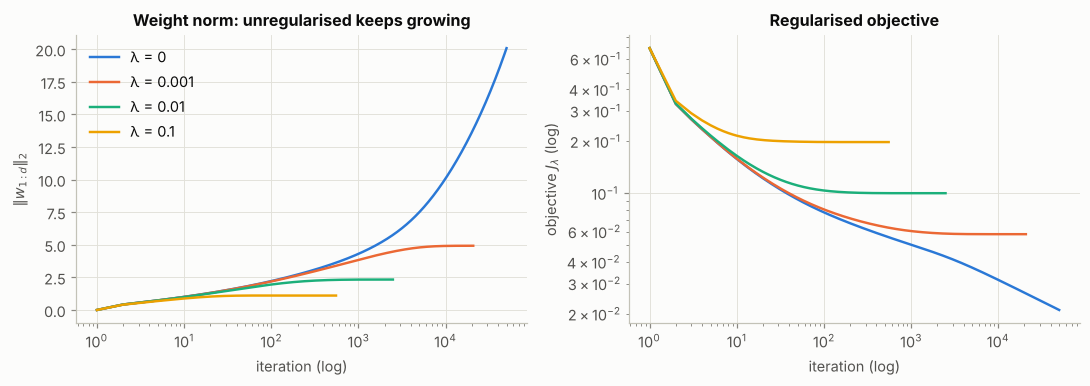

,iterations,converged,||w||,train accuracy,test accuracy,test log-loss
λ = 0,50000,False,20.0837,0.9934,0.9561,0.3064
λ = 0.001,20748,True,4.9269,0.9890,0.9737,0.0921
λ = 0.01,2485,True,2.3344,0.9802,0.9825,0.0812
λ = 0.1,553,True,1.1059,0.9714,0.9561,0.1431


In [16]:
lambdas = [0.0, 1e-3, 1e-2, 1e-1]
runs_l2 = {lam: LogisticRegressionScratch(l2=lam, max_iter=50_000, tol=1e-6).fit(XB_tr, yB_tr) for lam in lambdas}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for i, lam in enumerate(lambdas):
    r = runs_l2[lam]
    axes[0].plot(np.arange(1, r.n_iter_ + 1), r.weight_norm_history_, color=SERIES[i], label=f"λ = {lam:g}")
    axes[1].plot(np.arange(1, r.n_iter_ + 1), r.loss_history_, color=SERIES[i], label=f"λ = {lam:g}")
axes[0].set(xscale="log", xlabel="iteration (log)", ylabel=r"$\|w_{1:d}\|_2$",
            title="Weight norm: unregularised keeps growing")
axes[1].set(xscale="log", yscale="log", xlabel="iteration (log)", ylabel=r"objective $J_\lambda$ (log)",
            title="Regularised objective")
axes[0].legend()
plt.tight_layout()
plt.show()

l2_tab = pd.DataFrame({
    "iterations": [runs_l2[l].n_iter_ for l in lambdas],
    "converged": [runs_l2[l].converged_ for l in lambdas],
    "||w||": [np.linalg.norm(runs_l2[l].coef_[1:]) for l in lambdas],
    "train accuracy": [accuracy_score(yB_tr, runs_l2[l].predict(XB_tr)) for l in lambdas],
    "test accuracy": [accuracy_score(yB_te, runs_l2[l].predict(XB_te)) for l in lambdas],
    "test log-loss": [log_loss(yB_te, runs_l2[l].predict_proba(XB_te)) for l in lambdas],
}, index=[f"λ = {l:g}" for l in lambdas])
display(l2_tab)

With $\lambda=0$, gradient descent never meets the tolerance and $\lVert\mathbf w\rVert$ keeps growing.
The growth is only logarithmic in the iteration count, which is why the training accuracy after 50,000
iterations is still just below 100 % even though the perceptron proves a perfect separator exists. The
predicted probabilities become over-confident: the test log-loss is more than three times that of the
regularised fits (0.31 vs about 0.09), and test accuracy is lower too. Every $\lambda>0$ converges to a finite $\mathbf w$; larger $\lambda$ shrinks
the weights further and eventually underfits (λ = 0.1).

**Choosing λ without touching the test set.** 5-fold stratified cross-validation *inside the training
set*. The scaler is re-fitted on each training fold and the score is the validation log-loss.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lam_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
cv_rows = []
for lam in lam_grid:
    losses, accs = [], []
    for tr_idx, va_idx in cv.split(XB_tr_raw, yB_tr):
        sc = StandardScalerScratch().fit(XB_tr_raw[tr_idx])
        mdl = LogisticRegressionScratch(l2=lam, max_iter=50_000, tol=1e-6).fit(sc.transform(XB_tr_raw[tr_idx]), yB_tr[tr_idx])
        pv = mdl.predict_proba(sc.transform(XB_tr_raw[va_idx]))
        losses.append(log_loss(yB_tr[va_idx], pv))
        accs.append(accuracy_score(yB_tr[va_idx], (pv >= 0.5).astype(int)))
    cv_rows.append({"lambda": lam, "CV log-loss": np.mean(losses), "CV log-loss SD": np.std(losses),
                    "CV accuracy": np.mean(accs)})
cv_tab = pd.DataFrame(cv_rows).set_index("lambda")
display(cv_tab)
LAMBDA = float(cv_tab["CV log-loss"].idxmin())
print(f"Selected lambda = {LAMBDA:g} (lowest mean validation log-loss)")

,CV log-loss,CV log-loss SD,CV accuracy
lambda,,,
0.0001,0.1260,0.0330,0.9604
0.0010,0.0767,0.0241,0.9692
0.0100,0.0826,0.0212,0.9714
0.1000,0.1417,0.0253,0.9648
1.0000,0.2906,0.0244,0.9385


Selected lambda = 0.001 (lowest mean validation log-loss)


**4. Feature scaling and learning rate.** The raw features range from about 0.001 (fractal dimension)
to about 2500 (area). The Lipschitz constant, and with it the largest safe step, is then set by the
largest-scale feature, so the small-scale features barely move.

L (raw features) = 4.276e+05  vs  L (standardised) = 3.345


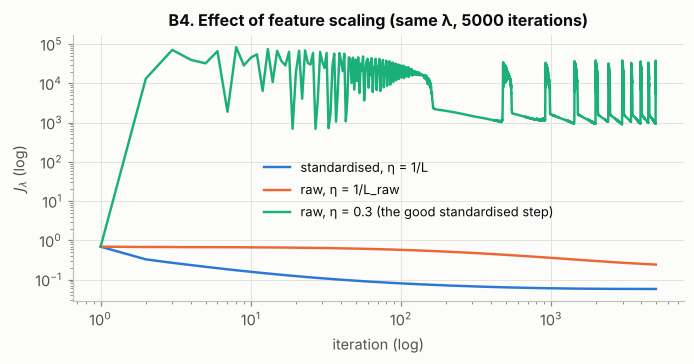

,final objective,train accuracy
"standardised, η = 1/L",0.0580,0.9890
"raw, η = 1/L_raw",0.2427,0.9253
"raw, η = 0.3 (the good standardised step)",8279.2257,0.1407


In [18]:
X1_raw = add_intercept(XB_tr_raw)
L_raw = np.linalg.norm(X1_raw, 2) ** 2 / (4 * len(X1_raw))
print(f"L (raw features) = {L_raw:.3e}  vs  L (standardised) = {L_B:.3f}")
scaling_runs = {
    "standardised, η = 1/L": LogisticRegressionScratch(l2=LAMBDA, max_iter=5000, tol=1e-8).fit(XB_tr, yB_tr),
    "raw, η = 1/L_raw": LogisticRegressionScratch(l2=LAMBDA, max_iter=5000, tol=1e-8).fit(XB_tr_raw, yB_tr),
    "raw, η = 0.3 (the good standardised step)": LogisticRegressionScratch(l2=LAMBDA, lr=0.3, max_iter=5000, tol=1e-8).fit(XB_tr_raw, yB_tr),
}
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for i, (name, r) in enumerate(scaling_runs.items()):
    ax.plot(np.arange(1, r.n_iter_ + 1), r.loss_history_, color=SERIES[i], label=name)
ax.set(xscale="log", yscale="log", xlabel="iteration (log)", ylabel=r"$J_\lambda$ (log)",
       title="B4. Effect of feature scaling (same λ, 5000 iterations)")
ax.legend(fontsize=8.5, loc="center", bbox_to_anchor=(0.55, 0.42))
plt.tight_layout()
plt.show()
display(pd.DataFrame({
    "final objective": [r.loss_history_[-1] for r in scaling_runs.values()],
    "train accuracy": [accuracy_score(yB_tr, r.predict(XB_tr if "standardised" in k else XB_tr_raw)) for k, r in scaling_runs.items()],
}, index=list(scaling_runs)))

On raw features the safe step $1/L_{\text{raw}}$ is tiny, so after 5000 iterations the model has
effectively learned only along the large-scale "area" direction and the objective is still far from
optimal. A step that works well on standardised data (η = 0.3) is wildly too large for raw data: the
logits explode and the loss oscillates at a high level. Standardising equalises curvature across
coordinates, which shrinks $\kappa$ of the Hessian, so one learning rate suits every direction.
Scaling does not change the regularised optimum's predictions *only if* the penalty is rescaled to
match. With a fixed λ, scaling changes the model as well as the optimisation, so it should be decided
before λ is tuned.

### B5. Evaluation on held-out test data

In [19]:
logit_B = LogisticRegressionScratch(l2=LAMBDA, max_iter=50_000, tol=1e-6).fit(XB_tr, yB_tr)
p_te = logit_B.predict_proba(XB_te)
yhat_te = (p_te >= 0.5).astype(int)
print(f"Final model: lambda = {LAMBDA:g}, {logit_B.n_iter_} iterations, converged = {logit_B.converged_}")


def clf_metrics(y, yhat, p=None):
    out = {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
           "recall": recall_score(y, yhat), "F1": f1_score(y, yhat)}
    if p is not None:
        out["ROC AUC"] = roc_auc_score(y, p)
        out["log-loss"] = log_loss(y, p)
    return out


display(pd.DataFrame([clf_metrics(yB_te, yhat_te, p_te)], index=["test (τ = 0.5)"]))
cm = confusion_matrix(yB_te, yhat_te, labels=[0, 1])
display(pd.DataFrame(cm, index=["true benign (0)", "true malignant (1)"],
                     columns=["pred. benign (0)", "pred. malignant (1)"]))

Final model: lambda = 0.001, 20748 iterations, converged = True


,accuracy,precision,recall,F1,ROC AUC,log-loss
test (τ = 0.5),0.9737,0.9756,0.9524,0.9639,0.9927,0.0921


,pred. benign (0),pred. malignant (1)
true benign (0),71,1
true malignant (1),2,40


,TP,FP,FN,TN,accuracy,precision,recall,F1
τ,,,,,,,,
0.1,40,6,2,66,0.9298,0.8696,0.9524,0.9091
0.2,40,1,2,71,0.9737,0.9756,0.9524,0.9639
0.3,40,1,2,71,0.9737,0.9756,0.9524,0.9639
0.5,40,1,2,71,0.9737,0.9756,0.9524,0.9639
0.7,38,0,4,72,0.9649,1.0000,0.9048,0.9500
0.9,34,0,8,72,0.9298,1.0000,0.8095,0.8947


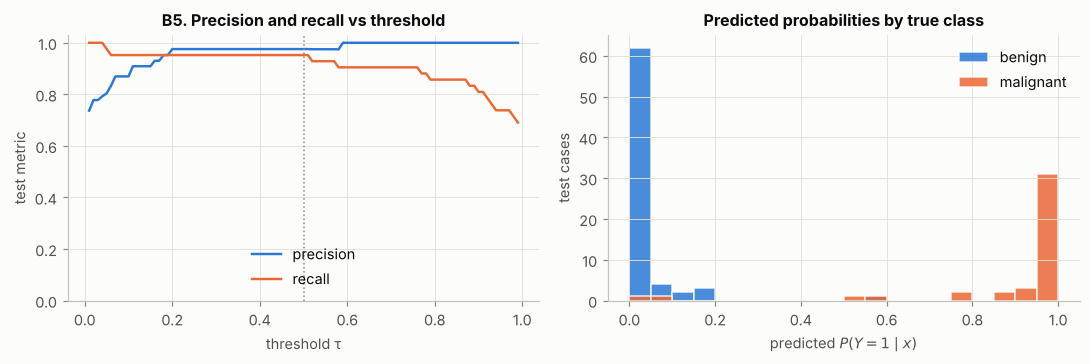

In [20]:
thresholds = [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
thr_rows = []
for tau in thresholds:
    yh = (p_te >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(yB_te, yh, labels=[0, 1]).ravel()
    thr_rows.append({"τ": tau, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                     **{k: v for k, v in clf_metrics(yB_te, yh).items()}})
display(pd.DataFrame(thr_rows).set_index("τ"))

grid = np.linspace(0.01, 0.99, 99)
prec = [precision_score(yB_te, (p_te >= t).astype(int), zero_division=1) for t in grid]
rec = [recall_score(yB_te, (p_te >= t).astype(int)) for t in grid]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(grid, prec, color=PAL["blue"], label="precision")
axes[0].plot(grid, rec, color=PAL["orange"], label="recall")
axes[0].axvline(0.5, color=MUTED, ls=":", lw=1)
axes[0].set(xlabel="threshold τ", ylabel="test metric", title="B5. Precision and recall vs threshold", ylim=(0, 1.03))
axes[0].legend(loc="lower center")
bins = np.linspace(0, 1, 21)
axes[1].hist(p_te[yB_te == 0], bins=bins, color=PAL["blue"], alpha=0.85, label="benign", edgecolor=SURFACE, linewidth=1)
axes[1].hist(p_te[yB_te == 1], bins=bins, color=PAL["orange"], alpha=0.85, label="malignant", edgecolor=SURFACE, linewidth=1)
axes[1].set(xlabel=r"predicted $P(Y=1\mid x)$", ylabel="test cases", title="Predicted probabilities by true class")
axes[1].legend()
plt.tight_layout()
plt.show()

In [21]:
from sklearn.linear_model import LogisticRegression  # reference implementation only

ref_B = LogisticRegression(C=1.0 / (LAMBDA * len(XB_tr)), max_iter=10_000, tol=1e-10).fit(XB_tr, yB_tr)
p_ref = ref_B.predict_proba(XB_te)[:, 1]
print(f"scikit-learn LogisticRegression with C = 1/(lambda n) = {1 / (LAMBDA * len(XB_tr)):.3f}")
print(f"  max |coef difference|            = {np.abs(np.r_[ref_B.intercept_, ref_B.coef_.ravel()] - logit_B.coef_).max():.2e}")
print(f"  max |test probability difference| = {np.abs(p_ref - p_te).max():.2e}")
print(f"  identical test labels: {np.array_equal(ref_B.predict(XB_te), yhat_te)}")

scikit-learn LogisticRegression with C = 1/(lambda n) = 2.198
  max |coef difference|            = 3.69e-04
  max |test probability difference| = 3.74e-05
  identical test labels: True


**Interpretation.**

* With malignant as the positive class, **recall** is the share of cancers caught and **precision**
  is the share of "malignant" calls that are right. The confusion matrix shows the errors directly.
  A false negative (a missed cancer) is far more costly than a false positive (an extra biopsy).
* **Threshold trade-off.** Lowering τ moves cases from FN to TP and from TN to FP: recall rises and
  precision falls. A screening setting would pick τ well below 0.5 and accept extra false alarms.
  The threshold is a *decision* about costs; the model's probabilities stay the same. On this test
  set the two missed cancers have $p<0.1$: the model is confidently wrong about them, so even
  τ = 0.1 does not catch them and only adds five false positives. Raising τ to 0.9 misses 8 of the
  42 cancers. Threshold tuning cannot fix confident errors; it only trades errors near the boundary.
* **Why accuracy alone is not enough.** The classes are imbalanced (about 37 % malignant), so a
  classifier that always says "benign" scores about 63 % accuracy with zero recall. Accuracy also
  weights both error types equally and ignores how confident the probabilities are; log-loss and the
  histogram do not.
* The scikit-learn reference with the matching $C=1/(\lambda n)$ reproduces our coefficients to
  optimiser tolerance. Students who compare against the *default* `C=1.0` will see differences. Those
  come from a different penalty strength, not from a bug.

> **TA note (Part B).** Expect test accuracy of about 0.95–0.99 for any sensible split and λ;
> one test case is 0.9 percentage points of 114. Precision and recall swap meaning if the student
> keeps scikit-learn's coding (benign = 1); either is fine if stated. The **finite-difference
> maximum error must be around 1e-7 or smaller**: around 1e-2 means a wrong gradient. Look out for
> unstable `np.log(sigmoid(...))` (`RuntimeWarning: divide by zero`), a penalised intercept with
> no justification, λ or τ chosen on the test set, and "did not converge" being missed or
> misexplained. The separability of the training set is the real reason the unregularised model
> never converges.

---
## Part C: PCA, covariance and eigenanalysis (`load_breast_cancer`)

Breast cancer is used here because its 30 correlated features make PCA non-trivial and it feeds
straight into Part E. **Data preparation:** we reuse the Part B split. Every statistic below comes
from the **455 training rows**; the 114 test rows are only projected with training parameters
(C3). Section C1 works on the *raw* training features to show why scaling matters. C2–C3 use the
training-standardised features.

### C1. Statistical properties of the data

In [22]:
sel = ["mean radius", "mean perimeter", "mean area", "mean texture", "mean smoothness", "mean fractal dimension"]
idx = [list(bc.feature_names).index(f) for f in sel]
Xs_raw = XB_tr_raw[:, idx]
n_c = len(Xs_raw)
mean_c = Xs_raw.sum(axis=0) / n_c
Xc_sel = Xs_raw - mean_c
cov_c = Xc_sel.T @ Xc_sel / (n_c - 1)
sd_c = np.sqrt(np.diag(cov_c))
corr_c = cov_c / np.outer(sd_c, sd_c)
assert np.allclose(cov_c, np.cov(Xs_raw, rowvar=False)) and np.allclose(corr_c, np.corrcoef(Xs_raw, rowvar=False))

short = ["radius", "perimeter", "area", "texture", "smoothness", "fractal dim."]
display(pd.DataFrame({"mean": mean_c, "variance (n-1)": np.diag(cov_c), "SD": sd_c}, index=short).T)
print("Sample covariance (raw units):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(pd.DataFrame(cov_c, index=short, columns=short))
print("Sample correlation:")
display(pd.DataFrame(corr_c, index=short, columns=short).round(3))

,radius,perimeter,area,texture,smoothness,fractal dim.
mean,14.1661,92.2159,659.5782,19.4177,0.0960,6.2715e-02
variance (n-1),12.8098,610.9359,129901.6289,18.4097,0.0002,4.8589e-05
SD,3.5791,24.7171,360.4187,4.2907,0.0143,6.9706e-03


Sample covariance (raw units):


,radius,perimeter,area,texture,smoothness,fractal dim.
radius,12.81,88.27,1273,5.012,0.00967,-0.007354
perimeter,88.27,610.9,8783,35.19,0.07988,-0.04207
area,1273,8783,1.299e+05,493,1.032,-0.6649
texture,5.012,35.19,493,18.41,-0.0007214,-0.002051
smoothness,0.00967,0.07988,1.032,-0.0007214,0.0002048,5.913e-05
fractal dim.,-0.007354,-0.04207,-0.6649,-0.002051,5.913e-05,4.859e-05


Sample correlation:


,radius,perimeter,area,texture,smoothness,fractal dim.
radius,1.000,0.998,0.987,0.326,0.189,-0.295
perimeter,0.998,1.000,0.986,0.332,0.226,-0.244
area,0.987,0.986,1.000,0.319,0.200,-0.265
texture,0.326,0.332,0.319,1.000,-0.012,-0.069
smoothness,0.189,0.226,0.200,-0.012,1.000,0.593
fractal dim.,-0.295,-0.244,-0.265,-0.069,0.593,1.000


* **Signs.** Radius, perimeter and area covary strongly and positively ($r>0.98$): all three
  measure size, and perimeter and area are close to deterministic functions of radius. Texture is
  weakly positively related to size. Fractal dimension (boundary complexity) is *negatively*
  correlated with radius ($r\approx-0.3$): larger cells tend to have smoother outlines relative to
  their size.
* **Magnitudes.** The raw covariances are dominated by units: var(area) is about $1.3\times10^5$,
  var(smoothness) about $2\times10^{-4}$. cov(radius, area) is huge and cov(smoothness, fractal dim.)
  is tiny, but that says nothing about *strength* of association, only about scale.
* **Covariance vs correlation.** $r_{jk}=s_{jk}/(s_js_k)$ is the covariance of standardised
  variables. It is unit-free and lies in $[-1,1]$, so it measures the strength of *linear*
  association. Covariance carries the product of the two units.
* **Why scaling matters for PCA.** PCA maximises variance, and variance is unit-dependent. On raw
  features, the first PC is essentially "area" because area has the largest numbers:

In [23]:
def pca_eig(X):
    Xc = X - X.mean(axis=0)
    S = Xc.T @ Xc / (len(X) - 1)
    lam, V = np.linalg.eigh(S)
    order = np.argsort(lam)[::-1]
    return lam[order], V[:, order]


lam_raw, V_raw = pca_eig(XB_tr_raw)
lam_std, _ = pca_eig(XB_tr)
top = np.argsort(np.abs(V_raw[:, 0]))[::-1][:3]
print(f"Raw features:          PC1 explains {lam_raw[0] / lam_raw.sum():.1%} of variance; largest |loadings|: "
      + ", ".join(f"{bc.feature_names[j]} ({V_raw[j, 0]:+.3f})" for j in top))
print(f"Standardised features: PC1 explains {lam_std[0] / lam_std.sum():.1%}")

Raw features:          PC1 explains 98.1% of variance; largest |loadings|: worst area (+0.852), mean area (+0.517), area error (+0.057)
Standardised features: PC1 explains 44.6%


PCA on raw features (equivalently, on the covariance matrix) gives a PC1 that is "worst area plus
mean area" with 98 % of the variance. That reflects measurement units, not structure. Standardising
(equivalently, PCA on the correlation matrix) gives every feature equal prior weight; then PC1
explains about 44 % and is a broad "size and shape irregularity" axis.

### C2. Covariance matrix and eigendecomposition

The class below is the PCA implementation reused in Parts D and E. It supports the
eigendecomposition route (`method="eigh"`) and the SVD route (`method="svd"`).

In [24]:
class PCAScratch:
    """PCA via eigendecomposition of S = Xc^T Xc / (n-1) or via the SVD of Xc.

    Keep n_components, or the smallest k with cumulative explained variance >= variance_threshold.
    Sign convention: each component's largest-|loading| entry is positive (deterministic output).
    """

    def __init__(self, n_components=None, variance_threshold=None, method="eigh"):
        self.n_components, self.variance_threshold, self.method = n_components, variance_threshold, method

    def fit(self, X):
        n = X.shape[0]
        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_
        if self.method == "eigh":
            self.cov_ = Xc.T @ Xc / (n - 1)
            lam, V = np.linalg.eigh(self.cov_)          # ascending order for symmetric matrices
            order = np.argsort(lam)[::-1]               # sort descending, reorder vectors consistently
            lam, V = lam[order], V[:, order]
        elif self.method == "svd":
            _, s, Vt = np.linalg.svd(Xc, full_matrices=False)
            lam, V = s ** 2 / (n - 1), Vt.T             # eigenvalues of S from singular values of Xc
            self.singular_values_ = s
        else:
            raise ValueError(self.method)
        signs = np.sign(V[np.argmax(np.abs(V), axis=0), np.arange(V.shape[1])])
        V = V * signs
        self.all_eigenvalues_ = lam
        self.all_components_ = V.T                      # rows = principal directions
        self.explained_variance_ratio_all_ = lam / lam.sum()
        cum = np.cumsum(self.explained_variance_ratio_all_)
        if self.variance_threshold is not None:
            k = int(np.searchsorted(cum, self.variance_threshold - 1e-12) + 1)
        elif self.n_components is not None:
            k = int(self.n_components)
        else:
            k = len(lam)
        self.k_ = k
        self.components_ = self.all_components_[:k]
        self.explained_variance_ = lam[:k]
        self.explained_variance_ratio_ = self.explained_variance_ratio_all_[:k]
        return self

    def transform(self, X):
        return (X - self.mean_) @ self.components_.T

    def inverse_transform(self, Z):
        return Z @ self.components_ + self.mean_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


pca_C = PCAScratch(variance_threshold=0.90, method="eigh").fit(XB_tr)
S = pca_C.cov_
print(f"S shape {S.shape};  max |S - S^T| = {np.abs(S - S.T).max():.2e}  (symmetric up to rounding)")
print(f"smallest eigenvalue of S = {pca_C.all_eigenvalues_.min():.3e} >= 0 (up to rounding);  "
      f"trace(S) = {np.trace(S):.4f} = sum of eigenvalues = {pca_C.all_eigenvalues_.sum():.4f}")
print(f"(trace is 30 x n/(n-1) = {30 * len(XB_tr) / (len(XB_tr) - 1):.4f}, because the scaler used ddof=0 and S uses n-1)")

S shape (30, 30);  max |S - S^T| = 0.00e+00  (symmetric up to rounding)
smallest eigenvalue of S = 1.241e-04 >= 0 (up to rounding);  trace(S) = 30.0661 = sum of eigenvalues = 30.0661
(trace is 30 x n/(n-1) = 30.0661, because the scaler used ddof=0 and S uses n-1)


**$S$ is positive semidefinite.** For any $\mathbf v$,
$\mathbf v^\top S\mathbf v=\frac{1}{n-1}\mathbf v^\top X_c^\top X_c\mathbf v=\frac{1}{n-1}\lVert X_c\mathbf v\rVert^2\ge0$.
This quantity is the sample variance of the projections $X_c\mathbf v$, and a variance cannot be
negative. $S$ is only semidefinite (not definite) whenever $\operatorname{rank}(X_c)<d$. That happens
when $n-1<d$, because centring removes one dimension, or when features are linearly dependent.
Here $S$ is positive definite, but its smallest eigenvalues are tiny, again because of near-collinear
size features.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
eigenvalue,13.4075,5.5758,2.8817,1.9825,1.6904,1.1992,0.6658,0.4853,0.3863,0.3505,0.3032,0.2723
explained ratio,0.4459,0.1855,0.0958,0.0659,0.0562,0.0399,0.0221,0.0161,0.0128,0.0117,0.0101,0.0091
cumulative,0.4459,0.6314,0.7272,0.7932,0.8494,0.8893,0.9114,0.9276,0.9404,0.9521,0.9622,0.9712


Smallest k with cumulative explained variance >= 90%: k = 7 (91.14%)


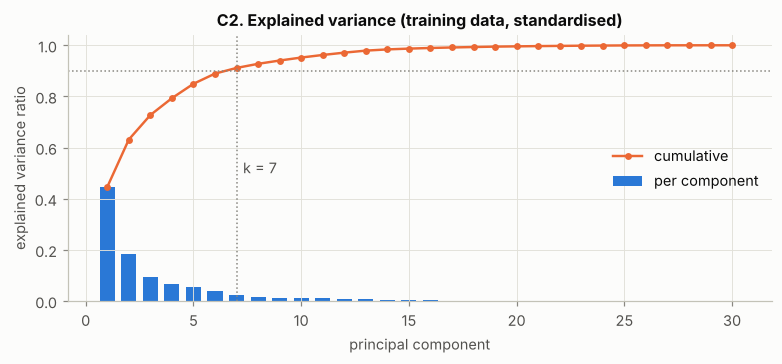

In [25]:
evr = pca_C.explained_variance_ratio_all_
eig_tab = pd.DataFrame({"eigenvalue": pca_C.all_eigenvalues_, "explained ratio": evr, "cumulative": np.cumsum(evr)},
                       index=[f"PC{i + 1}" for i in range(len(evr))])
display(eig_tab.head(12).T)
k_C = pca_C.k_
print(f"Smallest k with cumulative explained variance >= 90%: k = {k_C} ({np.cumsum(evr)[k_C - 1]:.2%})")

fig, ax = plt.subplots(figsize=(7.2, 3.4))
pcs = np.arange(1, len(evr) + 1)
ax.bar(pcs, evr, color=PAL["blue"], width=0.7, label="per component")
ax.plot(pcs, np.cumsum(evr), "o-", color=PAL["orange"], ms=3.5, label="cumulative")
ax.axhline(0.9, color=MUTED, ls=":", lw=1)
ax.axvline(k_C, color=MUTED, ls=":", lw=1)
ax.text(k_C + 0.3, 0.5, f"k = {k_C}", color=INK2)
ax.set(xlabel="principal component", ylabel="explained variance ratio",
       title="C2. Explained variance (training data, standardised)", ylim=(0, 1.04))
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

### C3. Projection, reconstruction and SVD

Projection: $Z_k=X_cV_k$. Reconstruction: $\hat X=Z_kV_k^\top+\bar{\mathbf x}^\top$, an orthogonal
projection onto the principal subspace. On the data PCA was fitted to, the reconstruction error is
exactly the variance left out:
$$\lVert X_c-X_cV_kV_k^\top\rVert_F^2=(n-1)\sum_{j>k}\lambda_j .$$
We check this identity numerically, and also measure the error on the *test* rows, which were not
used to fit $V_k$.

Projected shapes: (455, 7) (114, 7)
max |train reconstruction MSE - (n-1)*sum(discarded eigenvalues)/(n d)| = 4.44e-16
k = 7: train MSE 0.0886, test MSE 0.0910


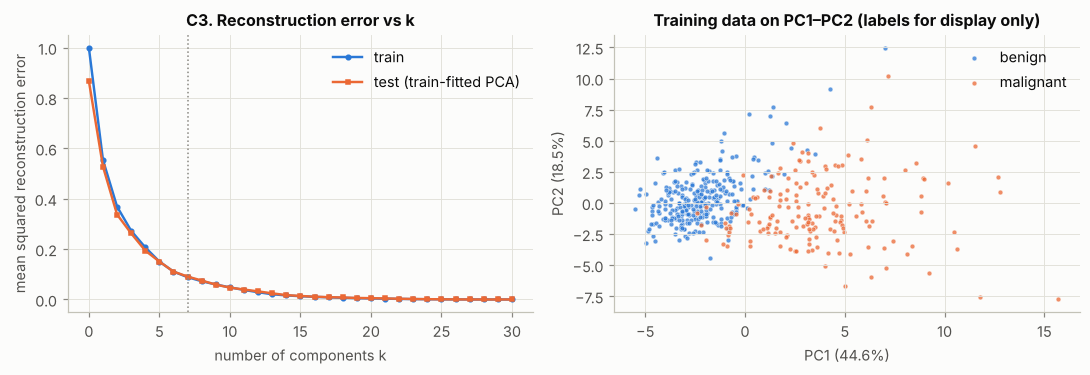

In [26]:
Z_tr_C = pca_C.transform(XB_tr)
Z_te_C = pca_C.transform(XB_te)
print("Projected shapes:", Z_tr_C.shape, Z_te_C.shape)
lam_all = pca_C.all_eigenvalues_
ks = np.arange(0, 31)
rec_tr, rec_te, theory = [], [], []
for kk in ks:
    Vk = pca_C.all_components_[:kk]
    rec_tr.append(np.mean((XB_tr - ((XB_tr - pca_C.mean_) @ Vk.T @ Vk + pca_C.mean_)) ** 2))
    rec_te.append(np.mean((XB_te - ((XB_te - pca_C.mean_) @ Vk.T @ Vk + pca_C.mean_)) ** 2))
    theory.append((len(XB_tr) - 1) * lam_all[kk:].sum() / XB_tr.size)
print(f"max |train reconstruction MSE - (n-1)*sum(discarded eigenvalues)/(n d)| = "
      f"{np.max(np.abs(np.array(rec_tr) - np.array(theory))):.2e}")
print(f"k = {k_C}: train MSE {rec_tr[k_C]:.4f}, test MSE {rec_te[k_C]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(ks, rec_tr, "o-", ms=3, color=PAL["blue"], label="train")
axes[0].plot(ks, rec_te, "s-", ms=3, color=PAL["orange"], label="test (train-fitted PCA)")
axes[0].axvline(k_C, color=MUTED, ls=":", lw=1)
axes[0].set(xlabel="number of components k", ylabel="mean squared reconstruction error",
            title="C3. Reconstruction error vs k")
axes[0].legend()
for cls, col, name in [(0, PAL["blue"], "benign"), (1, PAL["orange"], "malignant")]:
    m = yB_tr == cls
    axes[1].scatter(Z_tr_C[m, 0], Z_tr_C[m, 1], s=10, color=col, alpha=0.75, label=name,
                    edgecolors=SURFACE, linewidths=0.4)
axes[1].set(xlabel=f"PC1 ({evr[0]:.1%})", ylabel=f"PC2 ({evr[1]:.1%})",
            title="Training data on PC1–PC2 (labels for display only)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [27]:
pca_svd = PCAScratch(variance_threshold=0.90, method="svd").fit(XB_tr)
lam_e, lam_s = pca_C.all_eigenvalues_, pca_svd.all_eigenvalues_
print(f"Same k selected: eigh k = {pca_C.k_}, SVD k = {pca_svd.k_}")
print(f"max |lambda_eigh - sigma^2/(n-1)| = {np.abs(lam_e - lam_s).max():.2e}  (relative {np.abs(lam_e - lam_s).max() / lam_e[0]:.1e})")
print(f"explained-variance ratios identical to {np.abs(pca_C.explained_variance_ratio_ - pca_svd.explained_variance_ratio_).max():.1e}")

Ve, Vs = pca_C.all_components_, pca_svd.all_components_
cosines = np.abs(np.sum(Ve * Vs, axis=1))                       # |cos| between matching components
rel_gap = np.minimum(np.abs(np.diff(np.r_[np.inf, lam_e])), np.abs(np.diff(np.r_[lam_e, -np.inf]))) / lam_e[0]
comp_tab = pd.DataFrame({"eigenvalue": lam_e, "nearest gap / lambda_1": rel_gap,
                         "angle(v_eigh, v_svd) [deg]": np.degrees(np.arccos(np.clip(cosines, -1, 1)))},
                        index=[f"PC{i + 1}" for i in range(len(lam_e))])
with pd.option_context("display.float_format", "{:.2e}".format):
    display(comp_tab.iloc[list(range(8)) + [27, 28, 29]])
# Subspace comparison: principal angles between the two k-dimensional subspaces.
cos_angles = np.linalg.svd(pca_C.components_ @ pca_svd.components_.T, compute_uv=False)
P_e = pca_C.components_.T @ pca_C.components_
P_s = pca_svd.components_.T @ pca_svd.components_
print(f"Principal angles between the two {k_C}-D subspaces: max {np.degrees(np.arccos(np.clip(cos_angles, -1, 1))).max():.2e} degrees;  "
      f"||P_eigh - P_svd||_2 = {np.linalg.norm(P_e - P_s, 2):.2e}")

Same k selected: eigh k = 7, SVD k = 7
max |lambda_eigh - sigma^2/(n-1)| = 8.44e-15  (relative 6.3e-16)
explained-variance ratios identical to 3.3e-16


,eigenvalue,nearest gap / lambda_1,"angle(v_eigh, v_svd) [deg]"
PC1,1.34e+01,5.84e-01,0.00e+00
PC2,5.58e+00,2.01e-01,0.00e+00
PC3,2.88e+00,6.71e-02,1.71e-06
PC4,1.98e+00,2.18e-02,0.00e+00
PC5,1.69e+00,2.18e-02,1.21e-06
PC6,1.20e+00,3.66e-02,1.21e-06
PC7,6.66e-01,1.35e-02,1.21e-06
PC8,4.85e-01,7.38e-03,0.00e+00
PC28,1.51e-03,5.62e-05,0.00e+00
PC29,7.60e-04,4.74e-05,0.00e+00


Principal angles between the two 7-D subspaces: max 1.91e-06 degrees;  ||P_eigh - P_svd||_2 = 3.37e-15


* The two routes give the same eigenvalues to about $10^{-14}$, the same $k$ and the same principal
  subspace (principal angles about $10^{-6}$ degrees, i.e. rounding error). Individual eigenvectors
  also agree once signs are fixed. The signs are arbitrary ($\mathbf v$ and $-\mathbf v$ are both
  unit eigenvectors), which is why the class fixes a sign convention.
* **Nearly repeated eigenvalues.** A perturbation of size $\varepsilon$ rotates an eigenvector by
  about $\varepsilon/\text{gap}$. Here the smallest relative gap is about $5\times10^{-5}$, still huge
  compared with rounding ($\sim10^{-16}$), so every vector agrees. When two eigenvalues almost
  coincide, only their 2-D *span* is well determined, and the two methods can return different
  vectors inside it. The small constructed example below shows this, and it is why PCA results are
  compared via subspaces (principal angles, projector difference) rather than vector by vector.

In [28]:
rng_C = np.random.default_rng(SEED)
n_demo = 200
Q_full, _ = np.linalg.qr(np.column_stack([np.ones(n_demo), rng_C.standard_normal((n_demo, 4))]))
U_ = Q_full[:, 1:]                                      # orthonormal columns, orthogonal to 1 -> centred data
V_, _ = np.linalg.qr(rng_C.standard_normal((4, 4)))
lam_design = np.array([25.0, 9.0, 9.0 * (1 - 1e-6), 1.0])   # lambda_2 and lambda_3 differ by 1e-6 (relative)
Xc_demo = U_ @ np.diag(np.sqrt(lam_design * (n_demo - 1))) @ V_.T
E_demo = 1e-4 * rng_C.standard_normal(Xc_demo.shape)       # tiny perturbation of every data entry


def vec_angles(A, B):
    return np.degrees(np.arccos(np.clip(np.abs(np.sum(A * B, axis=1)), 0, 1)))


def plane_angle(A, B):
    c = np.linalg.svd(A @ B.T, compute_uv=False)
    return np.degrees(np.arccos(np.clip(c.min(), -1, 1)))


p0, p1 = PCAScratch().fit(Xc_demo), PCAScratch().fit(Xc_demo + E_demo)
print("designed eigenvalues:", p0.all_eigenvalues_.round(8))
print("eigh vs SVD on the same data, angle per component [deg]:",
      vec_angles(p0.all_components_, PCAScratch(method="svd").fit(Xc_demo).all_components_).round(6))
print("after a 1e-4 perturbation, angle per component [deg]:   ", vec_angles(p0.all_components_, p1.all_components_).round(4))
print(f"after the perturbation, angle between the PC2-PC3 planes:  {plane_angle(p0.all_components_[1:3], p1.all_components_[1:3]):.4f} deg")

designed eigenvalues: [25.  9.  9.  1.]
eigh vs SVD on the same data, angle per component [deg]: [0. 0. 0. 0.]
after a 1e-4 perturbation, angle per component [deg]:    [ 0.0002 74.9666 74.9666  0.0004]
after the perturbation, angle between the PC2-PC3 planes:  0.0004 deg


Perturbing each entry by about $10^{-4}$ barely moves PC1, PC4 or the PC2–PC3 *plane*, but it
rotates PC2 and PC3 by a large angle *inside* that plane, because their eigenvalues differ by only
$10^{-6}$ relative. The rounding differences between `eigh` and `svd` act like a perturbation of size
about $10^{-16}$. That is why the two methods may return different individual vectors for (nearly)
repeated eigenvalues, while any rotation of the pair inside the plane is an equally valid eigenbasis.
Here, as in the breast-cancer data, the two methods happen to agree exactly; the subspace comparison
is the robust check either way.
* **Eigenvalues of $S$ and singular values of $X_c$.** If $X_c=U\Sigma V^\top$, then
  $S=\frac{1}{n-1}X_c^\top X_c=V\frac{\Sigma^2}{n-1}V^\top$. So $\lambda_j=\sigma_j^2/(n-1)$, and the
  right singular vectors of $X_c$ are the principal directions. Also $Z=X_cV=U\Sigma$, so the scores
  come straight from the SVD. The SVD route avoids forming $S$ and so, as in Part A, avoids squaring
  the condition number. This matters for the smallest components, not for the leading ones that PCA keeps.

> **TA note (Part C).** With the full breast-cancer data standardised, the eigenvalue ratios are
> 0.443, 0.190, 0.094, … and **k = 7 reaches 90 % (91.0 %)**. Training-only fits give the same k for
> nearly every split. On iris (standardised), PC1–PC2 explain 72.96 % + 22.85 % = 95.8 %, so k = 2.
> Small differences in eigenvalues come from ddof (n vs n−1) and the subset used. The ratios do not
> depend on ddof. Look out for: `np.linalg.eig` instead of `eigh` with no sorting (eigh returns
> ascending order); the eigenvector *columns* not reordered along with the eigenvalues; comparing
> eigenvectors element-wise without handling sign; and reconstruction error that does not reach 0
> at k = d.

---
## Part D: K-means clustering and evaluation (`load_iris`)

The four numerical features of all 150 flowers are used for clustering. The species labels are
**not** used for fitting, initialisation or choosing K; they are used only afterwards, for ARI and
contingency tables.

### D1. Mathematical formulation

$$J(\mathbf c,\boldsymbol\mu)=\sum_{i=1}^n\lVert\mathbf x_i-\boldsymbol\mu_{c_i}\rVert_2^2
=\sum_{k=1}^K\sum_{i:\,c_i=k}\lVert\mathbf x_i-\boldsymbol\mu_k\rVert_2^2 .$$
$J$ is the within-cluster sum of squares (WCSS): the total squared Euclidean distance from each
point to the representative of its cluster. Minimising it asks for $K$ compact groups, each
summarised by one centre.

**Assignment step** (fix $\boldsymbol\mu$, optimise $\mathbf c$). $J$ is a sum of separate terms, one per
$i$, each depending only on $c_i$. It is minimised by $c_i=\arg\min_k\lVert\mathbf x_i-\boldsymbol\mu_k\rVert^2$.
The current assignment is one of the candidates, so the new $J$ cannot be larger. Breaking ties in
favour of the current cluster makes the decrease strict whenever a label changes.

**Update step** (fix $\mathbf c$, optimise $\boldsymbol\mu$). $J$ separates over clusters.
$J_k(\boldsymbol\mu_k)=\sum_{i\in C_k}\lVert\mathbf x_i-\boldsymbol\mu_k\rVert^2$ has gradient
$-2\sum_{i\in C_k}(\mathbf x_i-\boldsymbol\mu_k)$ and Hessian $2|C_k|I\succ0$, so the unique minimiser is the mean
$\boldsymbol\mu_k=\frac{1}{|C_k|}\sum_{i\in C_k}\mathbf x_i$. Again, $J$ cannot increase.

**Termination but not global optimality.** $J\ge0$ never increases, and strictly decreases
whenever the partition changes. There are finitely many partitions ($\le K^n$), so the algorithm
stops after finitely many iterations. This is *block-coordinate descent* on a non-convex,
combinatorial objective; minimising $J$ exactly is NP-hard in general. The stopping point is only a
fixed point: no single assignment or update step helps. Which fixed point is reached depends on
the initial centroids. D2 shows single runs getting stuck at $J\approx142.75$ when the best value
found is $78.85$.

### D2. From-scratch implementation

**Empty clusters.** If cluster $k$ loses all its points, its centroid is moved to the point with the
largest current squared distance to its own centroid, the worst-fitted point, and that point joins
cluster $k$. Its cost drops from $d^2>0$ to $0$ and nobody else's cost changes, so $J$ still
decreases, and the cluster count stays at $K$. (Alternatives that students may reasonably use:
re-sampling with k-means++, dropping the cluster with a warning, or keeping the old centroid. Any is
fine if stated and justified.)

In [29]:
def sq_dists(X, C):
    """Squared Euclidean distances, shape (n, K), vectorised via ||x||^2 - 2 x.c + ||c||^2."""
    d2 = (X ** 2).sum(axis=1)[:, None] - 2.0 * X @ C.T + (C ** 2).sum(axis=1)[None, :]
    return np.maximum(d2, 0.0)                         # clip tiny negative values from cancellation


class KMeansScratch:
    """Lloyd's algorithm with random (Forgy) or k-means++ initialisation and n_init restarts."""

    def __init__(self, n_clusters=3, init="k-means++", n_init=1, max_iter=300, random_state=None):
        self.n_clusters, self.init, self.n_init = n_clusters, init, n_init
        self.max_iter, self.random_state = max_iter, random_state

    def _init_centroids(self, X, rng):
        n, K = X.shape[0], self.n_clusters
        if isinstance(self.init, np.ndarray):
            return self.init.astype(float).copy()
        if self.init == "random":                      # K distinct data points chosen uniformly
            return X[rng.choice(n, size=K, replace=False)].astype(float)
        if self.init == "k-means++":                   # D^2 sampling
            C = [X[rng.integers(n)]]
            for _ in range(1, K):
                d2 = sq_dists(X, np.array(C)).min(axis=1)
                C.append(X[rng.choice(n, p=d2 / d2.sum())])
            return np.array(C, dtype=float)
        raise ValueError(self.init)

    @staticmethod
    def _objective(X, C, labels):
        return float(((X - C[labels]) ** 2).sum())

    def _single_run(self, X, rng):
        C = self._init_centroids(X, rng)
        labels = None
        history = []                                   # (stage, J) after every half-step
        n_empty = 0
        converged = False
        for it in range(1, self.max_iter + 1):
            D2 = sq_dists(X, C)
            new = D2.argmin(axis=1)
            if labels is not None:
                # tie-break in favour of the current cluster
                keep = D2[np.arange(len(X)), labels] <= D2[np.arange(len(X)), new]
                new = np.where(keep, labels, new)
            history.append(("assign", self._objective(X, C, new)))
            if labels is not None and np.array_equal(new, labels):
                converged = True
                break
            labels = new
            # empty-cluster handling: move the centroid to the worst-fitted point
            for k in range(self.n_clusters):
                if not np.any(labels == k):
                    n_empty += 1
                    cost = ((X - C[labels]) ** 2).sum(axis=1)
                    far = int(np.argmax(cost))
                    labels[far] = k
                    C[k] = X[far]
            C = np.array([X[labels == k].mean(axis=0) for k in range(self.n_clusters)])
            history.append(("update", self._objective(X, C, labels)))
        return C, labels, self._objective(X, C, labels), history, it, converged, n_empty

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)
        best = None
        for _ in range(self.n_init):
            run = self._single_run(X, rng)
            if best is None or run[2] < best[2]:
                best = run
        (self.cluster_centers_, self.labels_, self.inertia_, self.history_,
         self.n_iter_, self.converged_, self.n_empty_events_) = best
        self.objective_curve_ = np.array([J for stage, J in self.history_ if stage == "update"])
        return self

    def predict(self, X):
        return sq_dists(X, self.cluster_centers_).argmin(axis=1)

    def transform(self, X):
        """Euclidean distances to every centroid, shape (n, K)."""
        return np.sqrt(sq_dists(X, self.cluster_centers_))


iris = load_iris()
X_ir, y_ir = iris.data, iris.target                    # y_ir used ONLY after fitting, for evaluation
X_ir_std = StandardScalerScratch().fit_transform(X_ir)
print("iris:", X_ir.shape, "features:", iris.feature_names)

iris: (150, 4) features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


**Correctness checks** before using the implementation:

1. $J$ never increases over any half-step.
2. Starting from the same centroids, the result matches `sklearn.cluster.KMeans` (reference only).
3. Empty-cluster handling works when a centroid is deliberately placed far from all the data.

In [30]:
from sklearn.cluster import KMeans  # reference implementation only, for validation

km_check = KMeansScratch(3, init="random", random_state=SEED).fit(X_ir_std)
J_seq = np.array([J for _, J in km_check.history_])
print(f"1. monotone: max increase over all half-steps = {np.max(np.diff(J_seq)):.2e} (<= 0 required)")

C0 = X_ir_std[[0, 50, 100]]
mine = KMeansScratch(3, init=C0).fit(X_ir_std)
ref = KMeans(3, init=C0, n_init=1, algorithm="lloyd", tol=0).fit(X_ir_std)
print(f"2. same init as sklearn: J = {mine.inertia_:.6f} vs {ref.inertia_:.6f}; "
      f"same partition (ARI) = {adjusted_rand_score(mine.labels_, ref.labels_):.3f}")

C_bad = np.vstack([X_ir_std[[0, 50]], [[50.0, 50.0, 50.0, 50.0]]])
km_empty = KMeansScratch(3, init=C_bad).fit(X_ir_std)
print(f"3. far-away centroid: {km_empty.n_empty_events_} empty-cluster event(s) handled; "
      f"final cluster sizes {np.bincount(km_empty.labels_, minlength=3)}; J = {km_empty.inertia_:.2f}")

1. monotone: max increase over all half-steps = 0.00e+00 (<= 0 required)
2. same init as sklearn: J = 140.032753 vs 140.032753; same partition (ARI) = 1.000
3. far-away centroid: 1 empty-cluster event(s) handled; final cluster sizes [49 55 46]; J = 140.90


**Choosing K without labels.** The spec allows K either as a given hyperparameter or chosen by an
unsupervised criterion. Below: the elbow (WCSS vs K) and the mean silhouette coefficient on the
standardised features, best of 10 k-means++ starts per K.

K,2,3,4,5,6,7,8
WCSS,222.3617,139.8205,114.5046,90.8076,80.8602,71.6198,63.1034
silhouette,0.5818,0.4599,0.4133,0.3455,0.3354,0.3286,0.3217


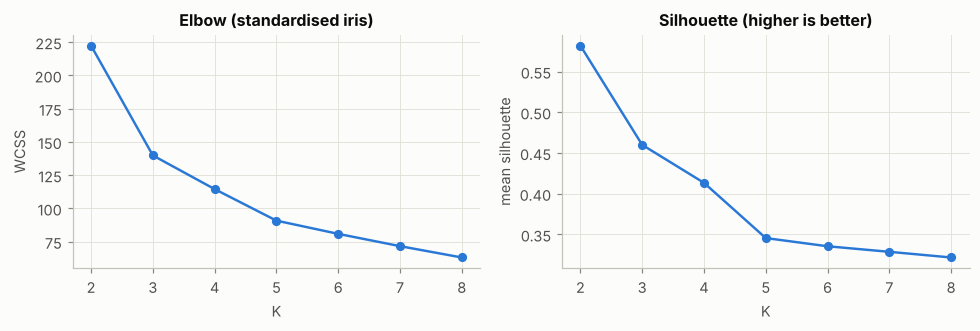

In [31]:
K_range = range(2, 9)
sel_rows = []
for K in K_range:
    km = KMeansScratch(K, init="k-means++", n_init=10, random_state=SEED).fit(X_ir_std)
    sel_rows.append({"K": K, "WCSS": km.inertia_, "silhouette": silhouette_score(X_ir_std, km.labels_)})
sel_tab = pd.DataFrame(sel_rows).set_index("K")
display(sel_tab.T)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.1))
axes[0].plot(sel_tab.index, sel_tab["WCSS"], "o-", color=PAL["blue"])
axes[0].set(xlabel="K", ylabel="WCSS", title="Elbow (standardised iris)")
axes[1].plot(sel_tab.index, sel_tab["silhouette"], "o-", color=PAL["blue"])
axes[1].set(xlabel="K", ylabel="mean silhouette", title="Silhouette (higher is better)")
plt.tight_layout()
plt.show()

The silhouette is highest at **K = 2**: *setosa* is clearly separate, while *versicolor* and
*virginica* overlap, so the unlabelled data genuinely look like two groups. The elbow is ambiguous
between 2 and 3. We follow the spec's first option and **treat K = 3 as a specified hyperparameter**
(three species are expected), and say so openly. Choosing 3 *because* the ARI against species is
higher would use the labels for model selection.

**Two initialisation strategies, 20 seeds each, one start per run (K = 3):**

best J  median J   worst J  runs within 1% of best  runs stuck (> 10% above best)  distinct final J values  \
space        init                                                                                                                      
raw          random      78.8514   78.8557  145.5252                      17                              3                        4   
             k-means++   78.8514   78.8557  142.7541                      18                              2                        3   
standardised random     139.8205  140.4918  191.0247                      18                              2                        6   
             k-means++  139.8205  140.0328  191.0247                      19                              1                        5   

                        mean iterations    ARI range  
space        init                                     
raw          random                7.30  0.420–0.730  
             k-means++             6.25  0.429–0.730  
standardised random                7.40  0.433–0.645  
             k-means++             6.30  0.433–0.645

raw: distinct local minima reached across 40 runs: [78.85, 78.86, 142.75, 145.53]
standardised: distinct local minima reached across 40 runs: [139.82, 139.83, 140.03, 140.08, 140.9, 191.02]


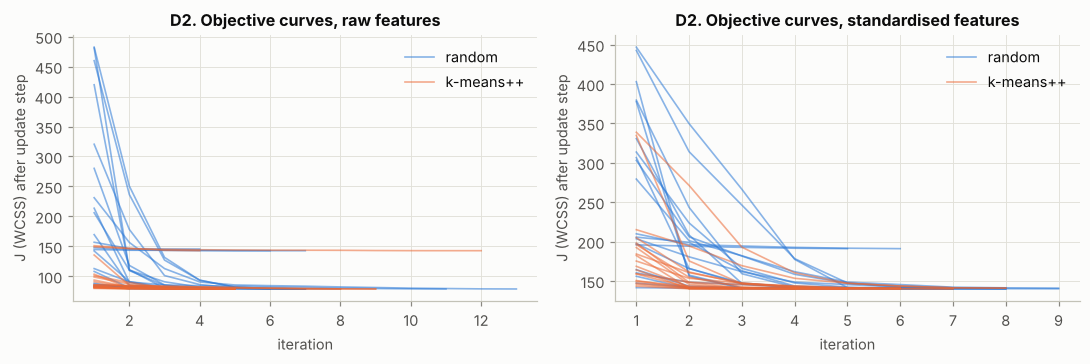

In [32]:
def init_study(X, init, seeds=range(20)):
    out = []
    for s in seeds:
        km = KMeansScratch(3, init=init, n_init=1, random_state=s).fit(X)
        out.append({"seed": s, "init": init, "J": km.inertia_, "iterations": km.n_iter_,
                    "ARI": adjusted_rand_score(y_ir, km.labels_), "curve": km.objective_curve_})
    return out


study = {sp: {init: init_study(Xsp, init) for init in ["random", "k-means++"]}
         for sp, Xsp in [("raw", X_ir), ("standardised", X_ir_std)]}
rows = []
for sp, d in study.items():
    for init, runs in d.items():
        J = np.array([r["J"] for r in runs])
        best_all = min(r["J"] for i in d.values() for r in i)
        rows.append({"space": sp, "init": init, "best J": J.min(), "median J": np.median(J), "worst J": J.max(),
                     "runs within 1% of best": int(np.sum(J <= 1.01 * best_all)),
                     "runs stuck (> 10% above best)": int(np.sum(J > 1.10 * best_all)),
                     "distinct final J values": len(np.unique(J.round(4))),
                     "mean iterations": np.mean([r["iterations"] for r in runs]),
                     "ARI range": f"{min(r['ARI'] for r in runs):.3f}–{max(r['ARI'] for r in runs):.3f}"})
init_tab = pd.DataFrame(rows).set_index(["space", "init"])
display(init_tab)
for sp in study:
    allJ = np.array([r["J"] for i in study[sp].values() for r in i])
    print(f"{sp}: distinct local minima reached across 40 runs: {np.unique(allJ.round(2)).tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for ax, sp in zip(axes, ["raw", "standardised"]):
    for i, init in enumerate(["random", "k-means++"]):
        for j, r in enumerate(study[sp][init]):
            ax.plot(np.arange(1, len(r["curve"]) + 1), r["curve"], color=SERIES[i], alpha=0.55, lw=1.1,
                    label=init if j == 0 else None)
    ax.set(xlabel="iteration", ylabel="J (WCSS) after update step", title=f"D2. Objective curves, {sp} features")
    ax.legend()
plt.tight_layout()
plt.show()

* Every curve decreases monotonically and stops within about 3–15 iterations, but not all at the
  same value. Across the 40 raw-feature runs, Lloyd's algorithm stopped at four different fixed
  points. Most are within 0.01 % of the best (78.85), but some runs are **stuck at J ≈ 142.75 or
  145.53**. In those, two centroids split the *setosa* group and one centroid covers versicolor plus
  virginica (ARI ≈ 0.43). On standardised features the poor fixed point is J ≈ 191.0.
* k-means++ spreads the initial centroids out and got stuck slightly less often here, but it is
  **not** a guarantee: it still hit a poor local minimum in 2 of 20 raw runs. The practical remedy
  is several restarts (`n_init`), keeping the lowest J. That is legitimate because it uses only the
  unsupervised objective. Choosing the restart with the best ARI would not be.

### D3. Scaling, evaluation and interpretation

In [33]:
km_raw = KMeansScratch(3, init="k-means++", n_init=10, random_state=SEED).fit(X_ir)
km_std = KMeansScratch(3, init="k-means++", n_init=10, random_state=SEED).fit(X_ir_std)
mu_ir, sd_ir = X_ir.mean(axis=0), X_ir.std(axis=0)
J_std_partition_in_raw = KMeansScratch._objective(X_ir, np.array([X_ir[km_std.labels_ == k].mean(0) for k in range(3)]), km_std.labels_)
J_raw_partition_in_std = KMeansScratch._objective(X_ir_std, np.array([X_ir_std[km_raw.labels_ == k].mean(0) for k in range(3)]), km_raw.labels_)

d3 = pd.DataFrame({
    "WCSS in its own space": [km_raw.inertia_, km_std.inertia_],
    "same partition's WCSS in raw space (cm²)": [km_raw.inertia_, J_std_partition_in_raw],
    "same partition's WCSS in std. space": [J_raw_partition_in_std, km_std.inertia_],
    "ARI vs species": [adjusted_rand_score(y_ir, km_raw.labels_), adjusted_rand_score(y_ir, km_std.labels_)],
    "cluster sizes": [np.bincount(km_raw.labels_).tolist(), np.bincount(km_std.labels_).tolist()],
}, index=["K-means on raw features", "K-means on standardised features"])
display(d3)
print(f"Agreement between the two partitions: ARI = {adjusted_rand_score(km_raw.labels_, km_std.labels_):.3f}; "
      f"{np.sum(pd.crosstab(km_raw.labels_, km_std.labels_).max(axis=1))} of 150 points in matched clusters")

short_f = ["sepal len", "sepal wid", "petal len", "petal wid"]
cent = pd.concat({
    "raw run (cm)": pd.DataFrame(km_raw.cluster_centers_, columns=short_f),
    "std. run, mapped back to cm": pd.DataFrame(km_std.cluster_centers_ * sd_ir + mu_ir, columns=short_f),
})
display(cent.round(2))
for name, km in [("raw", km_raw), ("standardised", km_std)]:
    ct = pd.crosstab(pd.Series(km.labels_, name=f"cluster ({name})"),
                     pd.Series(np.array(iris.target_names)[y_ir], name="species"))
    display(ct)

,WCSS in its own space,same partition's WCSS in raw space (cm²),same partition's WCSS in std. space,ARI vs species,cluster sizes
K-means on raw features,78.8514,78.8514,147.6238,0.7302,"[62, 50, 38]"
K-means on standardised features,139.8205,86.4269,139.8205,0.6201,"[50, 47, 53]"


Agreement between the two partitions: ARI = 0.804; 139 of 150 points in matched clusters


sepal len  sepal wid  petal len  petal wid
raw run (cm)                0       5.90       2.75       4.39       1.43
                            1       5.01       3.43       1.46       0.25
                            2       6.85       3.07       5.74       2.07
std. run, mapped back to cm 0       5.01       3.43       1.46       0.25
                            1       6.78       3.10       5.51       1.97
                            2       5.80       2.67       4.37       1.41

species,setosa,versicolor,virginica
cluster (raw),,,
0,0,48,14
1,50,0,0
2,0,2,36


species,setosa,versicolor,virginica
cluster (standardised),,,
0,50,0,0
1,0,11,36
2,0,39,14


* **Assignments.** Both runs isolate *setosa* perfectly. They differ in how they split
  versicolor from virginica. Raw features are dominated by petal length (variance about 3.1 cm²
  compared with about 0.19 for sepal width). Petal measurements are the most species-informative,
  so the raw clustering matches species better: **ARI 0.730 raw vs 0.620 standardised**.
  Standardising boosts sepal width, the weakest feature for species, and that makes the
  versicolor/virginica boundary worse. "Always standardise" is a default, not a law; the right
  scaling depends on which differences *should* count.
* **Centroids** (both in cm, for comparison) are close for setosa and shift for the two overlapping
  species, following the moved boundary.
* **WCSS is not comparable across spaces.** 78.85 is in cm²; 139.82 is in squared standard
  deviations, with total sum of squares $n\,d=600$ by construction. Changing the scale of a feature
  rescales its contribution to $J$, so the two numbers measure different objectives. A fair
  comparison evaluates both partitions in *one* space (columns 2–3), or uses scale-free ratios such
  as WCSS/TSS. In each space, the partition found there is (as it should be) the better one for that
  space's objective.
* **ARI** compares partitions up to relabelling and corrects for chance agreement, so it can be used
  with species labels without matching cluster IDs to species.
* **Cluster IDs are arbitrary.** $J$ is invariant to permuting the labels $1,\dots,K$, so "cluster 0"
  is whichever centroid happened to be initialised first. Comparing IDs to class codes directly
  (e.g. `accuracy_score(y, labels)`) is meaningless without an explicit matching step.
* **Assumptions and limitations.** K-means minimises squared Euclidean distance, so it favours
  compact, roughly spherical, similar-sized clusters separated by straight (Voronoi) boundaries.
  Elongated or overlapping groups such as versicolor and virginica are split along the
  highest-variance direction instead. Squared distances let a single outlier pull a centroid strongly
  (the mean is not robust). The result depends on initialisation (local minima above), on K, and on
  feature scaling. It also gives a hard partition even when there is no cluster structure at all.

### D4. Clustering before and after PCA

,dimensions,variance retained,WCSS (own space),TSS (own space),WCSS / TSS,partition's WCSS in 4-D,ARI vs species
standardised 4-D,4,1.0000,139.8205,600.0000,0.2330,139.8205,0.6201
PCA 2-D,2,0.9581,115.1865,574.8792,0.2004,140.0247,0.6011


PC1 72.96% + PC2 22.85% = 95.81%;  partitions agree: ARI(4-D, 2-D) = 0.960, 2 point(s) change cluster


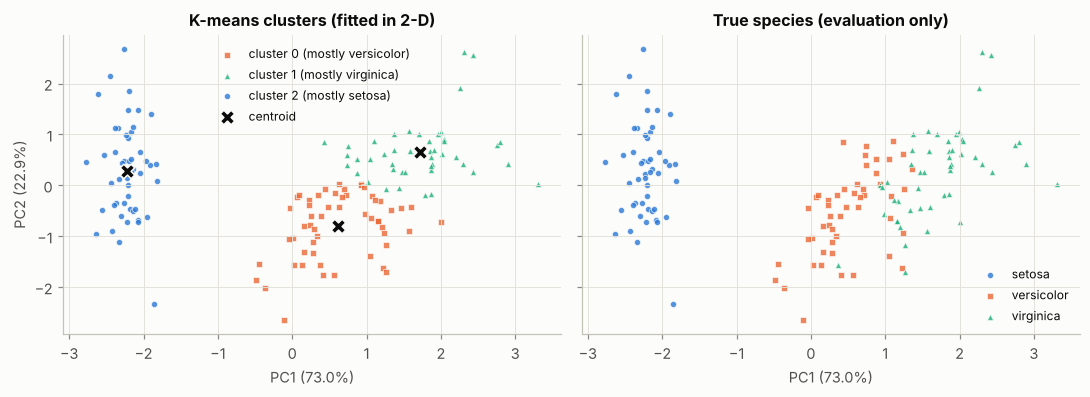

In [34]:
pca_D = PCAScratch(n_components=2).fit(X_ir_std)       # exploratory: fitted on all 150 standardised rows
Z_ir = pca_D.transform(X_ir_std)
km_4d = km_std
km_2d = KMeansScratch(3, init="k-means++", n_init=10, random_state=SEED).fit(Z_ir)
J_2d_in_4d = KMeansScratch._objective(X_ir_std, np.array([X_ir_std[km_2d.labels_ == k].mean(0) for k in range(3)]), km_2d.labels_)
tss_4d = ((X_ir_std - X_ir_std.mean(0)) ** 2).sum()
tss_2d = (Z_ir ** 2).sum()
d4 = pd.DataFrame({
    "dimensions": [4, 2],
    "variance retained": [1.0, pca_D.explained_variance_ratio_.sum()],
    "WCSS (own space)": [km_4d.inertia_, km_2d.inertia_],
    "TSS (own space)": [tss_4d, tss_2d],
    "WCSS / TSS": [km_4d.inertia_ / tss_4d, km_2d.inertia_ / tss_2d],
    "partition's WCSS in 4-D": [km_4d.inertia_, J_2d_in_4d],
    "ARI vs species": [adjusted_rand_score(y_ir, km_4d.labels_), adjusted_rand_score(y_ir, km_2d.labels_)],
}, index=["standardised 4-D", "PCA 2-D"])
display(d4)
print(f"PC1 {pca_D.explained_variance_ratio_[0]:.2%} + PC2 {pca_D.explained_variance_ratio_[1]:.2%} = "
      f"{pca_D.explained_variance_ratio_.sum():.2%};  partitions agree: ARI(4-D, 2-D) = "
      f"{adjusted_rand_score(km_4d.labels_, km_2d.labels_):.3f}, "
      f"{(150 - np.sum(pd.crosstab(km_4d.labels_, km_2d.labels_).max(axis=1)))} point(s) change cluster")

# For display only (after fitting): colour each cluster like the species most of its points belong to.
major = pd.crosstab(km_2d.labels_, y_ir).to_numpy().argmax(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), sharex=True, sharey=True)
mk = ["o", "s", "^"]
for k in range(3):
    m = km_2d.labels_ == k
    axes[0].scatter(Z_ir[m, 0], Z_ir[m, 1], s=16, color=SERIES[major[k]], marker=mk[major[k]], alpha=0.8,
                    edgecolors=SURFACE, linewidths=0.5, label=f"cluster {k} (mostly {iris.target_names[major[k]]})")
    m = y_ir == k
    axes[1].scatter(Z_ir[m, 0], Z_ir[m, 1], s=16, color=SERIES[k], marker=mk[k], alpha=0.8,
                    edgecolors=SURFACE, linewidths=0.5, label=iris.target_names[k])
axes[0].scatter(*km_2d.cluster_centers_.T, s=90, marker="X", color=INK, edgecolors=SURFACE, linewidths=1, label="centroid")
for ax, title in [(axes[0], "K-means clusters (fitted in 2-D)"), (axes[1], "True species (evaluation only)")]:
    ax.set(xlabel=f"PC1 ({pca_D.explained_variance_ratio_[0]:.1%})", title=title)
    ax.legend(fontsize=8)
axes[0].set_ylabel(f"PC2 ({pca_D.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()

* The first two components keep **95.8 %** of the standardised variance, so the 2-D clustering is
  almost the same as the 4-D one: ARI vs species is essentially unchanged, and only a few points
  change cluster.
* **WCSS is lower in 2-D**, but not because the clustering got better. Projection discards the
  variance along PC3 and PC4, and every squared distance in 2-D is less than or equal to the
  corresponding 4-D distance, because orthogonal projection never lengthens a vector. The fair
  comparisons are WCSS/TSS in each space (0.200 in 2-D vs 0.233 in 4-D: most of the discarded
  PC3/PC4 variance was within-cluster scatter, so the clusters look relatively tighter after
  projection) or evaluating both partitions in 4-D (140.02 for the 2-D partition vs 139.82: slightly
  worse, as it must be).
* **How projection changes things.** Distances become $\lVert V_2^\top(\mathbf x_i-\mathbf x_j)\rVert$.
  Differences along the dropped directions disappear, so points that differ mainly in PC3/PC4 are
  pushed together and can switch cluster. The algorithm sees less information. Here that loss is
  small, but PCA keeps *high-variance* directions, and those need not be the directions that
  separate the clusters (see Part F, Q7). Dropping low-variance noise directions can sometimes help
  K-means; dropping a low-variance but discriminative direction hurts it.

> **TA note (Part D).** Reference values (all 150 rows, best of several starts): **raw K = 3,
> J = 78.85, ARI = 0.730; standardised (ddof = 0) J = 139.82, ARI = 0.620; PCA 2-D retains 95.81 %.**
> A raw-feature J of about 142.75 is the well-known local minimum. A student whose standardised ARI
> is higher than the raw ARI should be asked to check their scaling. If they used `ddof=1` their
> standardised J is scaled by (n−1)/n (139.82 × 149/150 = 138.89), with identical partitions. Look
> out for: species labels used to pick K or initialise; `accuracy_score` on raw cluster IDs;
> comparing WCSS across spaces without comment; a Python loop over points instead of vectorised
> distances; no empty-cluster strategy.

---
## Part E: Integrated end-to-end ML pipeline

**Main configuration:** breast cancer, classification with the Part B logistic regression. A shorter
regression version on diabetes (Part A linear regression) follows, because the spec allows either
dataset.

### E1. Modular pipeline architecture

`IntegratedMLPipeline` chains the scratch components. **Every parameter is learned in `fit()` from
the training rows only:** scaler means and SDs, the PCA mean and components, the choice of $k$, and
the K-means centroids. `transform()` and `predict()` apply those stored parameters unchanged to any
new rows. The same class runs all three E2 configurations through its `mode` argument, so the
comparison differs in representation only.

One design detail: the distance columns $D$ are **centred with their training means** before the
supervised stage. Because the intercept is not penalised, centring is an *exact reparametrisation*:
$w_0+\sum_k w_k d_k=(w_0+\sum_k w_k\bar d_k)+\sum_k w_k(d_k-\bar d_k)$, with the same $w_k$ and the
same penalty, so the fitted model and its predictions do not change. The raw distances are all
positive with a large common mean, which makes them nearly collinear with the intercept column.
Gradient descent then needs about 250,000 iterations instead of about 23,000 to reach the same
optimum. E3 shows this in the condition numbers. (`center_distances=False` recovers the literal
$[Z\mid D]$.)

In [35]:
class IntegratedMLPipeline:
    """Standardise -> PCA (>= variance_threshold) -> K-means distance features -> supervised model.

    mode = "baseline": model on standardised features
           "pca":      model on the k principal-component scores Z
           "full":     model on X_aug = [Z | D], D_ik = ||z_i - mu_k||_2
    The estimator is any object with fit / predict (and optionally predict_proba); it is deep-copied
    so the template passed in is never modified.
    """

    def __init__(self, estimator, mode="full", variance_threshold=0.90, n_clusters=3,
                 kmeans_init="k-means++", kmeans_n_init=10, center_distances=True, random_state=SEED):
        if mode not in {"baseline", "pca", "full"}:
            raise ValueError(mode)
        self.estimator, self.mode, self.center_distances = estimator, mode, center_distances
        self.variance_threshold, self.n_clusters = variance_threshold, n_clusters
        self.kmeans_init, self.kmeans_n_init, self.random_state = kmeans_init, kmeans_n_init, random_state

    # ----- representation -------------------------------------------------
    def _fit_representation(self, X):
        self.scaler_ = StandardScalerScratch().fit(X)
        Xs = self.scaler_.transform(X)
        if self.mode in {"pca", "full"}:
            self.pca_ = PCAScratch(variance_threshold=self.variance_threshold).fit(Xs)
            Z = self.pca_.transform(Xs)
            if self.mode == "full":
                self.kmeans_ = KMeansScratch(self.n_clusters, init=self.kmeans_init,
                                             n_init=self.kmeans_n_init, random_state=self.random_state).fit(Z)
                D = self.kmeans_.transform(Z)
                self.d_mean_ = D.mean(axis=0) if self.center_distances else np.zeros(D.shape[1])
        return self

    def transform(self, X):
        """Feature matrix fed to the estimator (no intercept column), using fitted parameters only."""
        Xs = self.scaler_.transform(X)
        if self.mode == "baseline":
            return Xs
        Z = self.pca_.transform(Xs)
        if self.mode == "pca":
            return Z
        D = self.kmeans_.transform(Z) - self.d_mean_   # distances to the K centroids (train-centred)
        return np.hstack([Z, D])

    def design_matrix(self, X):
        """[1 | features]: the matrix whose conditioning E3 analyses."""
        return add_intercept(self.transform(X))

    # ----- supervised stage -----------------------------------------------
    def fit(self, X, y):
        self._fit_representation(X)
        self.model_ = copy.deepcopy(self.estimator)
        self.model_.fit(self.transform(X), y)
        return self

    def predict(self, X):
        return self.model_.predict(self.transform(X))

    def predict_proba(self, X):
        return self.model_.predict_proba(self.transform(X))

    @property
    def n_features_(self):
        if self.mode == "baseline":
            return self.scaler_.mean_.size
        return self.pca_.k_ + (self.n_clusters if self.mode == "full" else 0)

**Choosing K for the distance features, with training data only.** Fit the scaler and PCA on the
training set, then compute the silhouette of K-means in the training PCA space for K = 2, …, 8.
Neither the labels nor the test set are involved.

In [36]:
sc_E = StandardScalerScratch().fit(XB_tr_raw)
pca_E = PCAScratch(variance_threshold=0.90).fit(sc_E.transform(XB_tr_raw))
Z_E = pca_E.transform(sc_E.transform(XB_tr_raw))
sil_E = {K: silhouette_score(Z_E, KMeansScratch(K, n_init=10, random_state=SEED).fit(Z_E).labels_) for K in range(2, 9)}
display(pd.Series(sil_E, name="training silhouette").to_frame().T)
K_E = max(sil_E, key=sil_E.get)
print(f"PCA keeps k = {pca_E.k_} components; selected K = {K_E} (highest training silhouette)")

,2,3,4,5,6,7,8
training silhouette,0.3696,0.3481,0.3069,0.1889,0.19,0.1846,0.1743


PCA keeps k = 7 components; selected K = 2 (highest training silhouette)


### E2. Systematic pipeline evaluation

All three configurations use the same split (Part B), the same λ (chosen by cross-validation in B4),
the same `lr="auto"` rule ($1/L$ for *that* configuration's design matrix) and the same stopping
rule. The PCA representation and the full pipeline also share the same fitted scaler and PCA.

In [37]:
def logistic_template():
    return LogisticRegressionScratch(l2=LAMBDA, max_iter=100_000, tol=1e-6)


configs = {"Baseline (standardised X)": "baseline", "PCA representation (Z)": "pca", "Full pipeline ([Z | D])": "full"}
pipes = {name: IntegratedMLPipeline(logistic_template(), mode=mode, n_clusters=K_E).fit(XB_tr_raw, yB_tr)
         for name, mode in configs.items()}
E2_rows = []
for name, pl in pipes.items():
    p = pl.predict_proba(XB_te_raw)
    E2_rows.append({"configuration": name, "features": pl.n_features_,
                    **clf_metrics(yB_te, (p >= 0.5).astype(int), p),
                    "GD iterations": pl.model_.n_iter_, "converged": pl.model_.converged_})
E2 = pd.DataFrame(E2_rows).set_index("configuration")
display(E2)

,features,accuracy,precision,recall,F1,ROC AUC,log-loss,GD iterations,converged
configuration,,,,,,,,,
Baseline (standardised X),30,0.9737,0.9756,0.9524,0.9639,0.9927,0.0921,20748,True
PCA representation (Z),7,0.9737,0.9756,0.9524,0.9639,0.9967,0.0767,4133,True
Full pipeline ([Z | D]),9,0.9737,0.9756,0.9524,0.9639,0.9967,0.0762,23135,True


**Regression version (diabetes, Part A linear regression solved by QR).** Students who chose this
dataset should get numbers in this range. K is again chosen by the training silhouette.

In [38]:
sc_Er = StandardScalerScratch().fit(XA_tr_raw)
pca_Er = PCAScratch(variance_threshold=0.90).fit(sc_Er.transform(XA_tr_raw))
Z_Er = pca_Er.transform(sc_Er.transform(XA_tr_raw))
sil_Er = {K: silhouette_score(Z_Er, KMeansScratch(K, n_init=10, random_state=SEED).fit(Z_Er).labels_) for K in range(2, 9)}
K_Er = max(sil_Er, key=sil_Er.get)
reg_rows = []
for name, mode in configs.items():
    pl = IntegratedMLPipeline(LinearRegressionScratch(method="qr"), mode=mode, n_clusters=K_Er).fit(XA_tr_raw, yA_tr)
    yh = pl.predict(XA_te_raw)
    reg_rows.append({"configuration": name, "features": pl.n_features_, "test RMSE": rmse(yA_te, yh),
                     "test MAE": mean_absolute_error(yA_te, yh), "test R²": r2_score(yA_te, yh),
                     "kappa_2(design)": cond2(pl.design_matrix(XA_tr_raw))[0]})
print(f"diabetes: PCA keeps k = {pca_Er.k_} of 10 components; K = {K_Er} (training silhouette)")
display(pd.DataFrame(reg_rows).set_index("configuration"))

diabetes: PCA keeps k = 7 of 10 components; K = 2 (training silhouette)


,features,test RMSE,test MAE,test R²,kappa_2(design)
configuration,,,,,
Baseline (standardised X),10,53.8534,42.7941,0.4526,20.7335
PCA representation (Z),7,53.7814,42.8727,0.4541,2.7617
Full pipeline ([Z | D]),9,53.8863,43.1016,0.4519,10.4249


### E3. Feature representation and stability analysis

**1. Conditioning.** $\kappa_2$ of each *training* design matrix $[\mathbf 1\mid F]$, computed from its
singular values. The intercept is handled the same way in all three. Singular values below
$\max(n,p)\,u\,\sigma_1$ would count as zero and give $\kappa=\infty$; none do here. The second
column standardises every non-intercept column first, which separates genuine collinearity from
differences in column scale.

In [39]:
def standardise_cols(F):
    return (F - F.mean(0)) / F.std(0)


full = pipes["Full pipeline ([Z | D])"]
Z_tr_full = full.pca_.transform(full.scaler_.transform(XB_tr_raw))
D_tr_full = full.kmeans_.transform(Z_tr_full)                     # raw (uncentred) distances
designs = {name: pl.transform(XB_tr_raw) for name, pl in pipes.items()}
designs["Full pipeline, raw uncentred D"] = np.hstack([Z_tr_full, D_tr_full])
E3_rows = []
for name, F in designs.items():
    kap, sv, rank = cond2(add_intercept(F))
    kap_std = cond2(add_intercept(standardise_cols(F)))[0]
    E3_rows.append({"configuration": name, "shape": add_intercept(F).shape, "rank": rank,
                    "sigma_max": sv[0], "sigma_min": sv[-1], "kappa_2": kap, "kappa_2 (columns standardised)": kap_std})
display(pd.DataFrame(E3_rows).set_index("configuration"))
print("Mean / SD of the raw distance columns:", D_tr_full.mean(0).round(2), "/", D_tr_full.std(0).round(2))
print("GD iterations to tol 1e-6:", {n: pl.model_.n_iter_ for n, pl in pipes.items()})

# How much of each distance feature is a linear function of [1 | Z]?
Z1 = add_intercept(Z_tr_full)
r2_D = [1 - np.sum((D_tr_full[:, j] - Z1 @ solve_qr(Z1, D_tr_full[:, j])) ** 2) / np.sum((D_tr_full[:, j] - D_tr_full[:, j].mean()) ** 2)
        for j in range(D_tr_full.shape[1])]
print("R² of each distance feature regressed on [1 | Z] (1 = exactly collinear):", np.round(r2_D, 4))
print("Correlation between distance features:\n", np.corrcoef(D_tr_full, rowvar=False).round(3))

,shape,rank,sigma_max,sigma_min,kappa_2,kappa_2 (columns standardised)
configuration,,,,,,
Baseline (standardised X),"(455, 31)",31,78.0193,0.2373,328.7387,328.7387
PCA representation (Z),"(455, 8)",8,78.0193,17.3862,4.4874,1.0000
Full pipeline ([Z | D]),"(455, 10)",10,100.1865,11.8042,8.4873,8.0179
"Full pipeline, raw uncentred D","(455, 10)",10,180.3107,4.7832,37.6965,8.0179


Mean / SD of the raw distance columns: [6.4  4.78] / [2.14 3.11]
GD iterations to tol 1e-6: {'Baseline (standardised X)': 20748, 'PCA representation (Z)': 4133, 'Full pipeline ([Z | D])': 23135}
R² of each distance feature regressed on [1 | Z] (1 = exactly collinear): [0.4584 0.8436]
Correlation between distance features:
 [[ 1.    -0.002]
 [-0.002  1.   ]]


**2. Collinearity and linear separability.**

In [40]:
sep_rows = []
for name, mode in configs.items():
    pl = IntegratedMLPipeline(LogisticRegressionScratch(l2=0.0, max_iter=50_000, tol=1e-10), mode=mode,
                              n_clusters=K_E).fit(XB_tr_raw, yB_tr)
    F = pl.transform(XB_tr_raw)
    certified, _, n_upd = perceptron_certificate(F, yB_tr)
    sep_rows.append({"configuration": name, "features": F.shape[1],
                     "perceptron: separable certified?": f"yes ({n_upd} updates)" if certified else "no (200k-update budget)",
                     "unregularised LR training errors (50k its)": int(np.sum(pl.predict(XB_tr_raw) != yB_tr))})
display(pd.DataFrame(sep_rows).set_index("configuration"))

,features,perceptron: separable certified?,unregularised LR training errors (50k its)
configuration,,,
Baseline (standardised X),30,yes (8720 updates),3
PCA representation (Z),7,no (200k-update budget),11
Full pipeline ([Z | D]),9,no (200k-update budget),10


**3. Data leakage.** For comparison, a deliberately *leaky* variant fits the scaler, PCA and K-means
on train + test before training the classifier on the training rows. It is shown only to quantify
the effect.

In [41]:
X_all_raw = np.vstack([XB_tr_raw, XB_te_raw])
leaky = IntegratedMLPipeline(logistic_template(), mode="full", n_clusters=K_E)
leaky._fit_representation(X_all_raw)                   # <- leak: representation sees the test rows
leaky.model_ = copy.deepcopy(leaky.estimator).fit(leaky.transform(XB_tr_raw), yB_tr)
p_leaky = leaky.predict_proba(XB_te_raw)
cosL = np.linalg.svd(full.pca_.components_ @ leaky.pca_.components_.T, compute_uv=False) if leaky.pca_.k_ == full.pca_.k_ else None
print(f"PCA k: proper {full.pca_.k_}, leaky {leaky.pca_.k_}")
if cosL is not None:
    print(f"largest principal angle between proper and leaky PCA subspaces: {np.degrees(np.arccos(np.clip(cosL.min(), -1, 1))):.2f} degrees")
display(pd.DataFrame([clf_metrics(yB_te, (full.predict_proba(XB_te_raw) >= 0.5).astype(int), full.predict_proba(XB_te_raw)),
                      clf_metrics(yB_te, (p_leaky >= 0.5).astype(int), p_leaky)],
                     index=["proper (train-only fit)", "leaky (fit on train + test)"]))

PCA k: proper 7, leaky 7
largest principal angle between proper and leaky PCA subspaces: 9.69 degrees


,accuracy,precision,recall,F1,ROC AUC,log-loss
proper (train-only fit),0.9737,0.9756,0.9524,0.9639,0.9967,0.0762
leaky (fit on train + test),0.9737,0.9756,0.9524,0.9639,0.9967,0.0754


**Stability across splits.** One test set of 114 cases cannot resolve differences of one or two
predictions. We repeat the whole procedure on 20 stratified 80/20 splits (seeds 0–19). Every
pipeline is re-fitted from scratch on each training set, including the PCA $k$. λ and K are held at
the values chosen above.

accuracy              F1          recall         ROC AUC         log-loss           kappa_2        
                              mean     std    mean     std    mean     std    mean     std     mean     std      mean     std
configuration                                                                                                                
Baseline (standardised X)   0.9719  0.0129  0.9610  0.0188  0.9452  0.0355  0.9941  0.0054   0.0873  0.0362  318.4647  9.2147
PCA representation (Z)      0.9658  0.0175  0.9532  0.0236  0.9440  0.0321  0.9935  0.0054   0.0976  0.0382    4.4446  0.0704
Full pipeline ([Z | D])     0.9588  0.0199  0.9433  0.0271  0.9310  0.0353  0.9931  0.0056   0.0977  0.0393    8.3638  0.1343

PCA k chosen across splits: [7]
Paired accuracy difference, full - baseline: mean -0.0132, SD 0.0138, full better / tie / worse in 2/1/17 of 20 splits
Paired accuracy difference, PCA - baseline:  mean -0.0061, SD 0.0111


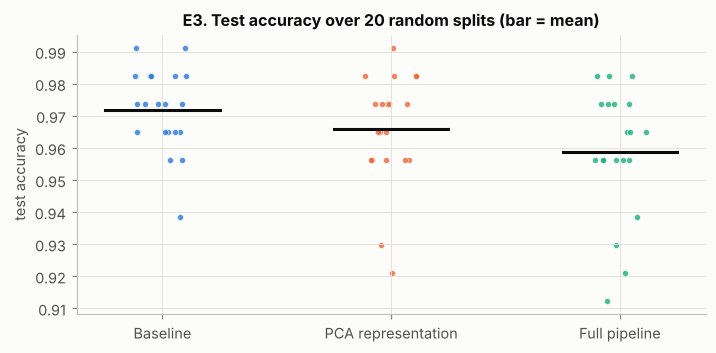

In [42]:
stab = []
for s in range(20):
    Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(X_bc, y_bc, test_size=0.2, random_state=s, stratify=y_bc)
    for name, mode in configs.items():
        pl = IntegratedMLPipeline(logistic_template(), mode=mode, n_clusters=K_E, random_state=s).fit(Xtr_s, ytr_s)
        p = pl.predict_proba(Xte_s)
        stab.append({"seed": s, "configuration": name, "k": pl.pca_.k_ if mode != "baseline" else np.nan,
                     "kappa_2": cond2(pl.design_matrix(Xtr_s))[0],
                     **clf_metrics(yte_s, (p >= 0.5).astype(int), p)})
stab = pd.DataFrame(stab)
agg = stab.groupby("configuration", sort=False)[["accuracy", "F1", "recall", "ROC AUC", "log-loss", "kappa_2"]].agg(["mean", "std"])
display(agg)
wide = stab.pivot(index="seed", columns="configuration", values="accuracy")
diff = wide["Full pipeline ([Z | D])"] - wide["Baseline (standardised X)"]
diff_pca = wide["PCA representation (Z)"] - wide["Baseline (standardised X)"]
print(f"PCA k chosen across splits: {sorted(stab['k'].dropna().astype(int).unique().tolist())}")
print(f"Paired accuracy difference, full - baseline: mean {diff.mean():+.4f}, SD {diff.std():.4f}, "
      f"full better / tie / worse in {np.sum(diff > 0)}/{np.sum(diff == 0)}/{np.sum(diff < 0)} of 20 splits")
print(f"Paired accuracy difference, PCA - baseline:  mean {diff_pca.mean():+.4f}, SD {diff_pca.std():.4f}")

fig, ax = plt.subplots(figsize=(6.6, 3.3))
for i, name in enumerate(configs):
    vals = wide[name].to_numpy()
    jitter = np.random.default_rng(i).uniform(-0.12, 0.12, len(vals))
    ax.scatter(np.full(len(vals), i) + jitter, vals, s=16, color=SERIES[i], alpha=0.8, edgecolors=SURFACE, linewidths=0.5)
    ax.plot([i - 0.25, i + 0.25], [vals.mean()] * 2, color=INK, lw=2)
ax.set_xticks(range(3), [n.split(" (")[0] for n in configs])
ax.set(ylabel="test accuracy", title="E3. Test accuracy over 20 random splits (bar = mean)")
plt.tight_layout()
plt.show()

**Interpretation (E2 and E3).**

* **Performance.** On the main split the three configurations make exactly the same test
  predictions at τ = 0.5 (one false positive, two false negatives); only the probabilities differ
  slightly (AUC, log-loss). One split cannot rank them. Over 20 splits the baseline is best on
  average. PCA to 7 components costs about 0.6 percentage points, and adding the distance features
  costs about another 0.7. The full pipeline is worse than the baseline in 17 of the 20 splits. Unsupervised
  compression keeps *variance*, not *class information*, and the two cluster distances do not add
  enough to make up for the discarded 9 % of variance.
* **Conditioning.** κ₂ falls from about 330 (baseline, 30 correlated features) to about 4.5 for
  $[\mathbf 1\mid Z]$. PCA scores are uncorrelated and centred, so the only spread left is the ratio
  of the largest to the smallest kept standard deviation; after column standardisation κ is exactly
  1. Adding the distances raises κ to about 8.5, or 8.0 with columns standardised. The distances are
  *partly* linear in Z (R² ≈ 0.46 and 0.84 when regressed on $[\mathbf 1\mid Z]$), so they add some
  collinearity. The rest is genuinely new, nonlinear information: distances are not linear functions
  of Z. Left uncentred, the distance columns have means of 6.4 and 4.8 (SDs 2.1 and 3.1) and are
  nearly parallel to the intercept, which pushes κ to about 38. That costs a factor of about 10 in gradient-descent
  iterations, but changes nothing in the fitted model.
* **Linear separability.** The 30-D standardised training set is separable (perceptron certificate).
  The 7-D PCA projection is not certified, and gradient descent leaves 11 training errors: projection
  merged some previously separable points. Adding the two distance features reduces that only to 10.
  Because distances are nonlinear in Z they can, in principle, improve linear separability; here the
  gain is marginal and not certified either. It also does not
  carry over to better test accuracy, which is a reminder that training separability is not
  generalisation.
* **Leakage.** Fitting the scaler, PCA and K-means on train + test rotates the 7-D principal subspace
  by up to about 10° (its least stable direction), and changes the representation every test point is
  mapped into, even though the test metrics barely move here. A small effect on one split does not
  make the leak acceptable. With fewer samples, more features, or K and k tuned on that data, leakage
  gives optimistic estimates. The rule is that *every* fitted quantity (means, SDs, eigenvectors, k,
  centroids, K, λ) is learned inside the training fold. This class enforces it by construction:
  `predict` and `transform` only read stored parameters.

> **TA note (Part E).** Exact numbers depend heavily on λ, K and the split. Look for the qualitative
> pattern, not specific values: (i) all three configurations reach high accuracy (about 0.95–0.98),
> and differences on a single split are one or two test cases; (ii) the PCA design matrix has a
> *much* smaller κ than the baseline, because its columns are uncorrelated; (iii) adding distance
> features raises κ again, and a lot if they are left uncentred, through collinearity with the
> intercept; (iv) a clear statement that the scaler, PCA and centroids are fitted on training rows
> only. A student who finds that the full pipeline does *not* help has probably done it right; do not
> reward tuning until it "wins". Red flags: `fit` called on the full dataset or on `X_test`; K or k
> chosen from test performance; a claimed improvement from one split with no measure of variability;
> scikit-learn `PCA`/`KMeans`/`LogisticRegression` *inside* `IntegratedMLPipeline`; logistic
> regression that hits `max_iter` without comment (likely with uncentred distances).

---
## Part F: Integrated mathematical reasoning and reproducibility

Each answer cites evidence computed earlier in this notebook.

**1. How do rank and conditioning influence parameter estimation in regression?**
*Rank* decides whether the estimate is unique. With full column rank, $X^\top X$ is invertible and
$\hat{\boldsymbol\beta}$ is unique; with rank deficiency there is a whole affine set of minimisers, and
only the minimum-norm one (SVD pseudo-inverse) is singled out. *Conditioning* decides how much the
estimate moves when the data or the arithmetic change, in three distinct ways.
(a) **Statistical:** $\operatorname{Var}(\hat{\boldsymbol\beta})=\sigma^2(X^\top X)^{-1}=\sigma^2\sum_i\mathbf v_i\mathbf v_i^\top/\sigma_i^2$,
so a small singular value inflates the variance along $\mathbf v_i$. In A4, SD$(\hat\beta_1)$ grew
from 0.05 to $3\times10^6$ as κ(X) grew from 2.4 to $1.75\times10^8$, while the identifiable sum
$\hat\beta_1+\hat\beta_2$ kept SD 0.04. In the diabetes data, the weakest direction mixes s1, s2, s3
and s5, which explains their large opposite-signed coefficients.
(b) **Numerical:** QR loses about $\log_{10}\kappa(X)$ digits and the normal equations about
$2\log_{10}\kappa(X)$. In A4 the normal equations were wrong by a factor of 2 at $\delta=10^{-8}$ while
QR was accurate to $2\times10^{-9}$.
(c) **Optimisation:** gradient descent converges at rate $1-1/\kappa(H)$. With κ(H) = 430 on diabetes
it needed 7,646 iterations; in Part E, logistic regression on the well-conditioned PCA design
(κ = 4.5) needed 4,133 iterations against 20,748 for the 30-feature baseline (κ = 329).
Remedies: QR or SVD instead of the normal equations, truncated SVD or ridge for unidentifiable
directions, and removing redundant features.

**2. Why is $X^\top X$ positive semidefinite, and when is it positive definite?**
$\mathbf v^\top X^\top X\mathbf v=\lVert X\mathbf v\rVert_2^2\ge0$ for every $\mathbf v$, which gives PSD. It equals 0
only if $X\mathbf v=\mathbf 0$, so $X^\top X$ is positive definite iff $X$ has full column rank ($n\ge p$
and no exact linear dependence among columns, the intercept included). Evidence: the diabetes design
has rank 11 of 11 and $\lambda_{\min}(X^\top X)=3.26>0$. A4 adds a practical caveat. At
$\delta=10^{-8}$, $X$ still has full rank in exact arithmetic, yet the *computed* $X^\top X$ has
κ ≈ $1.4\times10^{16}\approx1/u$: it is numerically singular. "Positive definite" is not the same as
"safely invertible in floating point". The same argument shows that $S=X_c^\top X_c/(n-1)$ is PSD (C2),
with $\lambda_{\min}(S)=1.2\times10^{-4}$ for breast cancer.

**3. How are the eigenvalues of a covariance matrix related to the singular values of a centred
data matrix?** If $X_c=U\Sigma V^\top$, then $S=V\frac{\Sigma^2}{n-1}V^\top$, so $\lambda_j=\sigma_j^2/(n-1)$.
The right singular vectors are the principal directions, and the scores are $Z=X_cV=U\Sigma$.
Verified in C3: the largest difference between the eigh eigenvalues and $\sigma_j^2/(n-1)$ was
$8\times10^{-15}$, with the same $k=7$ and the same 7-D subspace (principal angles about
$2\times10^{-6}$ degrees). It is the same identity as $\kappa(X^\top X)=\kappa(X)^2$ in Part A, applied
to $X_c$.

**4. How does a loss gradient determine the update direction in gradient descent, and what can
affect convergence?** By first-order Taylor expansion, $J(\mathbf w-\eta\mathbf g)\approx J(\mathbf w)-\eta\lVert\mathbf g\rVert^2$, so
$-\nabla J$ is the direction of steepest local decrease and its length sets the step together with η.
Convergence depends on: (i) **step size relative to curvature**. $\eta\le1/L$ guarantees descent;
much larger steps overshoot (in B4, η = 300 raised the loss from 0.69 to 26 on the first step and
increased it on 553 of 3000 steps). (ii) **Conditioning**, which sets the linear rate (A2's measured
slope matched $(1-1/\kappa(H))^{2t}$). (iii) **Feature scale**: raw breast-cancer features give
$L=4.3\times10^5$ against 3.3 standardised, and gradient descent stalls (B4); uncentred distance
features in Part E needed about 250,000 iterations instead of 23,000. (iv) **Whether a minimiser
exists at all**: the separable breast-cancer training set gives the unregularised loss no minimiser,
so ‖w‖ grows for ever and the stopping rule is never met; any λ > 0 restores a unique optimum
(λ = 0.001: 20,748 iterations; λ = 0.1: 553). (v) The **stopping criterion**: the gradient tolerance
bounds the parameter error by about $\lVert\nabla J\rVert/\lambda_{\min}$, which is why gradient descent
matched QR only to about $10^{-6}$ in A3.

**5. Why does logistic regression require a probabilistic model, and how does its likelihood lead to
a loss function?** The outcome is binary. A least-squares fit to 0/1 labels gives "probabilities"
outside [0, 1] and implicitly assumes Gaussian noise with constant variance, which is wrong for a
Bernoulli variable whose variance is $p(1-p)$. Modelling $Y\mid\mathbf x\sim\text{Bernoulli}(\sigma(\tilde{\mathbf x}^\top\mathbf w))$
gives a likelihood $\prod p_i^{y_i}(1-p_i)^{1-y_i}$. Its negative log is the binary cross-entropy, which
is convex with the simple gradient $\frac1n\tilde X^\top(\mathbf p-\mathbf y)$ (B2, verified to $8\times10^{-11}$ by
finite differences). The probabilistic output is what makes threshold choice (B5), log-loss and
calibration meaningful. L2 regularisation is then MAP estimation with a Gaussian prior on the
weights, which is exactly what fixed the separability problem.

**6. How does feature scaling affect distance-based clustering?** Squared Euclidean distance adds
the per-feature squared differences, so each feature's influence is proportional to its variance.
On raw iris, petal length (variance 3.1 cm²) dominates sepal width (0.19). Petal measurements are
also the most species-informative, so raw K-means matched the species better (ARI 0.730) than
standardised K-means (0.620), which gives the weak sepal-width feature equal weight. The two
partitions disagree on 11 of 150 flowers. WCSS values (78.85 cm² vs 139.82 in squared SD units)
measure different objectives and cannot be compared directly. Scaling is therefore a *modelling
decision* about which differences should count, not just a preprocessing step.

**7. Why can PCA retain most of the variance without preserving the structure most useful for
classification or clustering?** PCA is unsupervised: it ranks directions by variance and never sees
the labels. A direction with small variance can still carry the class boundary, and a
high-variance direction may be pure nuisance; on raw breast-cancer features, PC1 is "area" with
98 % of the variance because of units alone. Evidence: 7 components keep 91 % of the standardised
variance, but the training set goes from *certifiably separable* in 30-D to not certified in 7-D
(11 training errors), and test accuracy drops by 0.6 percentage points on average over 20 splits.
On iris, 2 components keep 95.8 % and ARI slips only from 0.620 to 0.601: there the dominant
directions *do* carry the cluster structure. Whether PCA keeps the useful structure is an empirical
question, not a consequence of the variance retained.

**8. How does chaining unsupervised representation learning (PCA + K-means) into supervised
learning affect bias–variance trade-offs and numerical conditioning?**
*Bias:* projecting to $k$ components restricts the classifier to functions of $Z$. If discriminative
information sits in the discarded directions, that is irreducible bias. The distance features
partly offset this, because they are nonlinear in $Z$ and enlarge the function class.
*Variance:* fewer parameters (8 or 10 instead of 31) lower the estimation variance. But every
unsupervised stage is itself estimated from the training sample, and K-means can land in different
local minima, so the representation varies from split to split. That adds variance of its own.
Across 20 splits the accuracy SD rose from 0.013 (baseline) to 0.018 (PCA) and 0.020 (full), and the
mean fell from 0.972 to 0.966 to 0.959. On this dataset the added bias and representation variance
outweigh the savings. *Conditioning:* PCA scores are orthogonal, so κ dropped from 329 to 4.5 and
gradient descent became 5× faster. Distance features re-introduce partial collinearity (κ 8.5, R² of
0.46 and 0.84 on Z) and, if left uncentred, near-collinearity with the intercept (κ 38, about 10× more
iterations). Because every stage is *fitted*, it must be fitted inside the training fold. The leaky
variant rotated the PCA subspace by up to 10° using test information.

### Reproducibility statement

* **Software:** Python, NumPy, pandas, Matplotlib, scikit-learn; exact versions are printed in the
  first code cell. No other packages are imported.
* **Data:** `load_diabetes`, `load_breast_cancer` and `load_iris` ship with scikit-learn; nothing is
  downloaded.
* **Randomness:** `SEED = 42` for every split, K-means initialisation, cross-validation fold and
  synthetic dataset; the stability study uses seeds 0–19. All generators are local
  `np.random.default_rng` objects, so re-running a single cell does not change any other cell's results.
* **Train/test discipline:** every fitted quantity (scaling statistics, PCA components and k,
  centroids, λ, K) is learned from training rows only. The species labels in Part D and the test
  labels in Parts B and E are used only for evaluation. The single exception is labelled: the leaky
  variant in E3, shown only to measure leakage.
* **Reference implementations** (`LinearRegression`, `LogisticRegression`, `KMeans` from
  scikit-learn) are used only to validate the scratch implementations, and are marked as such.
* **Execution:** the notebook runs top to bottom in a fresh kernel in about 1–2 minutes on a laptop-class CPU.
* **Assistance:** this reference solution was prepared for the teaching team with the help of Claude,
  an AI assistant (Anthropic). Every reported number is produced by the code in this notebook.

### Reference values at a glance

The table below is computed from the variables above, so it always matches this run.

In [43]:
glance = [
    ("A", "diabetes: train / test rows", f"{len(XA_tr)} / {len(XA_te)}"),
    ("A", "kappa_2(X), kappa_2(X^T X)", f"{kappa_A:.2f}, {kappa_A ** 2:.1f}"),
    ("A", "test RMSE (normal eq. = QR = GD)", f"{rmse(yA_te, lin_A['qr'].predict(XA_te)):.2f}"),
    ("A", "GD iterations (eta = 1/L, tol 1e-8)", f"{gd_A.n_iter_}"),
    ("B", "breast cancer: train / test rows, positive class", f"{len(XB_tr)} / {len(XB_te)}, malignant = 1"),
    ("B", "finite-difference max |error|", "~1e-10"),
    ("B", "lambda chosen by 5-fold CV (train only)", f"{LAMBDA:g}"),
    ("B", "test accuracy / precision / recall / F1 (tau = 0.5)",
     " / ".join(f"{v:.3f}" for v in list(clf_metrics(yB_te, yhat_te).values()))),
    ("B", "confusion matrix [TN FP; FN TP]", f"[{cm[0, 0]} {cm[0, 1]}; {cm[1, 0]} {cm[1, 1]}]"),
    ("C", "PCA k for >= 90% (train, standardised)", f"{k_C} ({np.cumsum(evr)[k_C - 1]:.1%})"),
    ("C", "PC1, PC2 explained ratio", f"{evr[0]:.3f}, {evr[1]:.3f}"),
    ("D", "iris K = 3, raw: J, ARI", f"{km_raw.inertia_:.2f}, {adjusted_rand_score(y_ir, km_raw.labels_):.3f}"),
    ("D", "iris K = 3, standardised: J, ARI", f"{km_std.inertia_:.2f}, {adjusted_rand_score(y_ir, km_std.labels_):.3f}"),
    ("D", "iris PCA 2-D: variance kept, J, ARI",
     f"{pca_D.explained_variance_ratio_.sum():.2%}, {km_2d.inertia_:.2f}, {adjusted_rand_score(y_ir, km_2d.labels_):.3f}"),
    ("E", "pipeline k, K (training silhouette)", f"{pca_E.k_}, {K_E}"),
    ("E", "kappa_2: baseline / PCA / full (centred D)",
     " / ".join(f"{cond2(pl.design_matrix(XB_tr_raw))[0]:.1f}" for pl in pipes.values())),
    ("E", "20-split mean test accuracy: baseline / PCA / full",
     " / ".join(f"{agg.loc[n, ('accuracy', 'mean')]:.3f}" for n in configs)),
]
display(pd.DataFrame(glance, columns=["part", "quantity", "value (seed 42)"]).set_index(["part", "quantity"]))

value (seed 42)
part quantity                                                                         
A    diabetes: train / test rows                                              353 / 89
     kappa_2(X), kappa_2(X^T X)                                           20.73, 429.9
     test RMSE (normal eq. = QR = GD)                                            53.85
     GD iterations (eta = 1/L, tol 1e-8)                                          7646
B    breast cancer: train / test rows, positive class         455 / 114, malignant = 1
     finite-difference max |error|                                              ~1e-10
     lambda chosen by 5-fold CV (train only)                                     0.001
     test accuracy / precision / recall / F1 (tau = ...  0.974 / 0.976 / 0.952 / 0.964
     confusion matrix [TN FP; FN TP]                                      [71 1; 2 40]
C    PCA k for >= 90% (train, standardised)                                  7 (91.1%)
     PC1, PC2 explained ratio                                             0.446, 0.185
D    iris K = 3, raw: J, ARI                                              78.85, 0.730
     iris K = 3, standardised: J, ARI                                    139.82, 0.620
     iris PCA 2-D: variance kept, J, ARI                         95.81%, 115.19, 0.601
E    pipeline k, K (training silhouette)                                          7, 2
     kappa_2: baseline / PCA / full (centred D)                      328.7 / 4.5 / 8.5
     20-split mean test accuracy: baseline / PCA / full          0.972 / 0.966 / 0.959